<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QVC_ApproximateEncoding_West2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Approximate amplitude encoding for adversarially robust quantum classifiers (West et al., 2024) step by step

This notebook re-implements, runs and checks the experiments of

> Maxwell T. West, Azar C. Nakhl, Jamie Heredge, Floyd M. Creevey, Lloyd C. L. Hollenberg, Martin Sevior and Muhammad Usman,
> "Drastic Circuit Depth Reductions with Preserved Adversarial Robustness by Approximate Encoding for Quantum Machine Learning",
> *Intelligent Computing* (2024), arXiv:2309.09424. https://doi.org/10.34133/icomputing.0100

**What it does.** A quantum variational classifier (QVC) must first load an image into a quantum state (amplitude encoding). Preparing that
state exactly needs a very deep circuit. The paper replaces the exact preparation by a cheap *approximate* one, accepts a state
fidelity of only about 60 %, and shows that (i) the circuit gets about two orders of magnitude shallower, (ii) the classification accuracy
stays almost the same and (iii) attacks crafted on a classical network transfer slightly *less well* to the approximately encoded quantum model.
The notebook builds the exact encoder (Qiskit), two approximate encoders (matrix-product-state style and variational), a 9-qubit QVC,
trains the QVC on each encoding, runs the paper's PGD attacks and prints the paper's claims next to its own numbers.

**How to run.** Open in Colab, choose a CPU runtime, then *Runtime -> Run all*. `FAST_MODE = True` (configuration cell) is a class demo; the committed run took 16.7 minutes on a busy shared laptop CPU (about 10 minutes on an idle one). `FAST_MODE = False` uses larger budgets that were estimated at 2-3 hours and were therefore not run for this notebook (the outputs below are from the FAST run). Everything is
simulated exactly, so no quantum hardware and no account is needed (`IBM_TOKEN` stays empty).

**What you get at the end.** Real MNIST / Fashion-MNIST visualisations, drawings of the exact and approximate encoding circuits and of the
QVC, a CNOT-count and depth comparison, clean and adversarial accuracy curves of ConvNet, ResNet-18 and the three QVCs, a noisy-circuit
study, a small "Shapes" experiment, and a table with a verdict per claim of the paper.

## The paper in one page

**Problem.** Loading classical data into a quantum state is generically exponential in the number of qubits and can erase any speed-up of a
quantum machine learning (QML) model. At the same time QML models, like classical ones, can be fooled by adversarial inputs.

**Decision.** Image classification (MNIST and Fashion-MNIST, 28 x 28) by a QVC; is it enough to prepare the input state only approximately?

**Encoding (Eq. 1).** Two neighbouring pixels form one complex amplitude: `|psi(x)> = (1/||x||) sum_j (x_{2j} + i x_{2j+1}) |j>`, so 784 pixels
need n = 9 qubits (512 amplitudes, the last 120 are zero). The *exact* preparation is Qiskit's state-preparation routine (Shende-Bullock-Markov, "SBM");
circuit depth about 2^9 and roughly a thousand CNOTs.

**Approximate preparation.** Three methods, each stopped when the prepared state reaches a target fidelity of 60 % with the true state:
1. *MPS*: repeatedly "disentangle" the state with two-qubit unitaries built from the eigenvectors of two-qubit reduced density matrices
   (k = 2, all neighbouring pairs in parallel, then the shifted pairs); the encoder is the inverse of this disentangler.
2. *GASP*: a genetic algorithm that searches gate sequences and angles (not rerun here, see the table below).
3. *Variational*: layers of one arbitrary rotation per qubit followed by a chain of CNOTs, optimised with Adam for 100 steps; add a layer and repeat if
   the target fidelity is not reached (at most 25 layers).

**Classifier.** Encoding `E(x)`, then L layers of arbitrary single-qubit rotations + a CNOT chain (`U(theta)`), then the Pauli-Z expectation values
of the qubits are the class scores; softmax + cross-entropy, Adam with learning rate 1e-3, 30 000 training images; one model per encoding.

**Attack.** Projected gradient descent (PGD) in the l-infinity ball of radius eps, three steps of size eps/3 with a random start, computed on a classical
ConvNet and *transferred* to ResNet-18 and to the QVCs (also: attacks computed on a QVC itself).

**Claims.** (C1) the approximate encoders need about two orders of magnitude fewer CNOTs than SBM at 60 % fidelity (Fig. 1d); (C2) the QVC keeps its
accuracy under random pixel noise even when the state fidelity drops to about 60-70 % (Fig. 1b); (C3) QVCs trained on approximate states have
accuracy comparable to the exact QVC (Fig. 2c,d); (C4) QVCs resist transferred ConvNet attacks far better than ConvNet/ResNet-18 (Fig. 2c,d, Fig. S5); (C5) the approximately
encoded QVCs are slightly *more* robust than the exact one (Fig. 2); (C6) they also resist attacks computed on a QVC (Fig. S5);
(C7) under two-qubit depolarising noise the approximate models keep their accuracy at noise levels 1-2 orders of magnitude higher (Fig. 3a);
(C8) on the "Shapes" data the CNOT savings persist (Fig. 3c) and (C9) a real IBM device (ibm_algiers) runs the approximate circuits but not the exact one (Fig. 3e).

### What follows the paper and what had to be chosen

The paper's numbers live in figures (histograms, accuracy curves) and are not printed, and its code is available "on request" only. Everything the text
does not fix is marked `# CHOICE:` in the code. The checks therefore compare *qualitative claims and orders of magnitude*, not tabulated values.

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST, Fashion-MNIST (28 x 28); 30 000 training images; 500 validation; 500 test | same two datasets from Hugging Face; class-balanced subsets: 400 / 2 000 training images (FAST / full), 100 / 500 test images, 100 / 200 of them attacked |
| Classes | 10 classes with 9 qubits; "observable `M_j` = Pauli-Z on qubit j" (so only 9 distinct single-qubit scores) | 10 classes: `Z_0 ... Z_8` and, for class 9, the parity `Z^(x)9` (CHOICE; the paper does not say how the tenth class is read out) |
| Exact encoder | Qiskit state preparation (SBM) | `qiskit.circuit.library.StatePreparation`, transpiled to `{cx, u}`; statevector checked against the target |
| MPS encoder | k = 2, parallel neighbouring pairs, then shifted pairs, stop at fidelity 60 % | as described; one *layer* = 4 even pairs + 4 odd pairs; stop after the first layer whose fidelity is >= 60 %; 2-qubit unitaries counted with Qiskit's synthesis (<= 3 CNOT each) |
| Variational encoder | rotation per qubit + CNOT chain, Adam 100 steps, add a layer if needed (<= 25) | same; Adam learning rate and the initialisation of a new layer are not given (CHOICE, see code) |
| GASP encoder | genetic algorithm, SLSQP, 200 generations | **not implemented** (hours of CPU per batch; the paper itself tests it only through the variational model); claim cannot be checked |
| QVC | L repeated layers, 20 layers in the noise study; Adam, lr 1e-3 | L = 8 (FAST) or 20 (full) layers, Adam with a larger learning rate and far fewer images and epochs (CPU budget); `RX/RY/RZ` replaced by the equivalent `Rot` gate |
| Attack | PGD, l-inf, 3 steps, alpha = eps/3, random start; attack strengths in the figures not listed | same; eps grid chosen by us (CHOICE) |
| Classical networks | a ConvNet and ResNet-18 (architectures not listed) | a small two-convolution ConvNet and a ResNet-18 with base width 16 (CPU budget) |
| Hardware | `ibm_algiers`, 27 qubits | **cannot be run**; replaced by an exact density-matrix simulation with two-qubit depolarising noise on a self-generated "Shapes" set |
| Shapes data | 8 x 8 images of "squares" and "crosses" at random positions (generator not given) | own generator (squares of side 2-3 px, crosses with arm length 1-2 px) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# We add PennyLane (draws and verifies the QVC), Qiskit + Aer (exact / approximate encoding circuits, noisy simulation) and the
# Hugging Face client. The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "qiskit", "qiskit_aer", "huggingface_hub", "pyarrow", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages present; skipping pip install.")

All packages present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True       # True: class demo (about 10 minutes). False: larger budgets (about 2-3 hours on a shared laptop CPU, dominated by the per-image variational encoder).

SEED       = 42            # CHOICE: the paper gives no seed
NQ         = 9             # paper: 9 qubits for a 28 x 28 image (Eq. 1)
IMG        = 28
N_CLASSES  = 10
FID_TARGET = 0.60          # paper: target fidelity of the approximate states (Fig. 1d, Fig. S4)

DATASETS   = ["mnist", "fmnist"]
N_TRAIN    = 400 if FAST_MODE else 2000    # paper: 30 000 training images (reduced for the CPU budget)
N_VAL      = 60 if FAST_MODE else 200      # paper: 500 validation images
N_TEST     = 100 if FAST_MODE else 500     # paper: 500 test images (clean accuracy)
N_ATK      = 100 if FAST_MODE else 200     # first N_ATK test images are attacked and re-encoded (paper: 500)

QVC_LAYERS = 8 if FAST_MODE else 20        # paper: 20-layer QVCs in the noise study (Fig. 3a); the other figures do not state L
EPOCHS     = 40 if FAST_MODE else 20
BATCH      = 50
LR_QVC     = 0.05          # CHOICE: paper uses 1e-3 with 30 000 images; we use fewer images and epochs, so a larger step
INIT_STD   = 2.0           # CHOICE: standard deviation of the initial rotation angles (not given in the paper)
N_SEEDS    = 1 if FAST_MODE else 2         # QVC training seeds (mean +- std in the tables)

ENC_STEPS  = 40 if FAST_MODE else 100   # paper: 100 Adam steps per variational layer count (FAST_MODE uses fewer to save time)
ENC_LR     = 0.15 if FAST_MODE else 0.1           # CHOICE: Adam learning rate of the variational encoder (not given)
ENC_MAX_LAYERS = 25        # paper: at most 25 layers
MPS_MAX_LAYERS = 12        # CHOICE: the paper gives no cap for the MPS layers
ENC_CHUNK  = 600           # images encoded at a time (memory)

N_DEPTH    = 10 if FAST_MODE else 60      # images per dataset whose circuits are built and transpiled with Qiskit (paper: 500)
EPS_LIST   = [0.0, 0.15, 0.3] if FAST_MODE else [0.0, 0.05, 0.1, 0.2, 0.3]   # CHOICE: attack strengths
EPS_MAIN   = 0.15 if FAST_MODE else 0.1   # paper uses eps = 0.1 for the hardware figure
EPS_QATT   = [0.2] if FAST_MODE else [0.1, 0.2, 0.3]   # strengths for attacks computed on the QVC itself (Fig. S5)
PGD_STEPS  = 3             # paper: three PGD steps, alpha = eps / 3
CNN_EPOCHS = 15 if FAST_MODE else 20
RES_WIDTH  = 16            # CHOICE: ResNet-18 base width (the standard 64 is too slow on a CPU)
NOISE_LEVELS = [0.0, 1e-3, 3e-3, 1e-2]   # two-qubit depolarising probability (Fig. 3a goes up to about 1e-2)
N_NOISE    = 10 if FAST_MODE else 30        # test images simulated with noise (density-matrix simulation of 9 qubits)
SWEEP_MPS, SWEEP_VAR = [0.2, 0.4, 0.8], [0.2, 0.4]   # extra target fidelities for the CNOT-versus-fidelity sweep (section 6)
N_SWEEP    = 40 if FAST_MODE else 100
PIXEL_NOISE = [0.0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]   # CHOICE: amplitudes of the uniform pixel noise of Fig. 1b

SH_NQ, SH_LAYERS = 5, 3    # Shapes: 8 x 8 images -> 5 qubits (paper), 3 variational layers (CHOICE; "only a few")
SH_TARGET  = 0.70          # paper: 70 % target fidelity for Shapes (Fig. 3c)
SH_TRAIN   = 300 if FAST_MODE else 1000
SH_TEST    = 60 if FAST_MODE else 150
SH_EPOCHS = 60           # Shapes QVC training epochs (CHOICE)
SH_P       = 1e-2          # CHOICE: depolarising noise standing in for the real device

DATA_DIR   = "data"        # parquet files from Hugging Face are cached here
IBM_TOKEN  = ""            # unused: every circuit is simulated, no quantum hardware is needed

In [3]:
import os, time, math, io, warnings, functools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector
import qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
import sklearn
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Hugging Face token (optional for these public datasets; MNIST / Fashion-MNIST are not gated). If you use a gated dataset in the
# exercises, put your own token into Colab Secrets (key HF_TOKEN) or the environment variable HF_TOKEN. It is never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(min(2, os.cpu_count() or 1))     # small tensors: more threads only add overhead on a shared machine
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})
CDT = torch.complex64
T0 = time.time()
print("torch", torch.__version__, "| pennylane", qml.version(), "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)
print("FAST_MODE =", FAST_MODE, "| qubits", NQ, "| QVC layers", QVC_LAYERS, "| train/val/test", N_TRAIN, N_VAL, N_TEST, "| seeds", N_SEEDS)

torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | numpy 2.5.4
FAST_MODE = True | qubits 9 | QVC layers 8 | train/val/test 400 60 100 | seeds 1


## 1. Data: MNIST and Fashion-MNIST

Both datasets are downloaded as Parquet files from the Hugging Face hub (`ylecun/mnist`, `zalando-datasets/fashion_mnist`; public, no gate) and cached in
`DATA_DIR`. We draw class-balanced random subsets of the training split (training and validation, disjoint) and of the test split.
Pixel values are scaled to [0, 1]. Only the rows we need are decoded.

In [4]:
from huggingface_hub import hf_hub_download
from PIL import Image

SPECS = {
    "mnist":  dict(repo="ylecun/mnist", sub="mnist", title="MNIST",
                   names=[str(i) for i in range(10)]),
    "fmnist": dict(repo="zalando-datasets/fashion_mnist", sub="fashion_mnist", title="Fashion-MNIST",
                   names=["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]),
}

def read_split(ds, split):
    sp = SPECS[ds]
    path = hf_hub_download(sp["repo"], f"{sp['sub']}/{split}-00000-of-00001.parquet", repo_type="dataset",
                           token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + ds))
    df = pd.read_parquet(path)
    return df, df["label"].values.astype(np.int64)

def balanced_pick(y, n, rng, exclude=()):
    """n indices with n/10 per class (class-balanced), not in `exclude`."""
    per = n // N_CLASSES; out = []
    ex = np.zeros(len(y), bool); ex[list(exclude)] = True
    for k in range(N_CLASSES):
        pool = np.flatnonzero((y == k) & ~ex)
        out.append(rng.choice(pool, per, replace=False))
    out = np.concatenate(out); return out[rng.permutation(len(out))]

def decode(df, idx):
    return np.stack([np.array(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"]))) for i in idx]).astype(np.float32) / 255.0

DATA = {}
for ds in DATASETS:
    df_tr, y_all = read_split(ds, "train"); df_te, y_te_all = read_split(ds, "test")
    r = np.random.default_rng(SEED)                                   # same subsets in every run
    i_tr = balanced_pick(y_all, N_TRAIN, r); i_va = balanced_pick(y_all, N_VAL, r, exclude=i_tr); i_te = balanced_pick(y_te_all, N_TEST, r)
    d = {}
    for nm, df, ii, yy in [("tr", df_tr, i_tr, y_all), ("va", df_tr, i_va, y_all), ("te", df_te, i_te, y_te_all)]:
        d["X" + nm] = torch.as_tensor(decode(df, ii).reshape(len(ii), -1)); d["y" + nm] = torch.as_tensor(yy[ii])
    d["n_full"] = dict(train=len(y_all), test=len(y_te_all))
    DATA[ds] = d
    print(f"{SPECS[ds]['title']:14s} full train {len(y_all)}, full test {len(y_te_all)} | used: train {tuple(d['Xtr'].shape)}, val {tuple(d['Xva'].shape)}, test {tuple(d['Xte'].shape)}")
del df_tr, df_te

MNIST          full train 60000, full test 10000 | used: train (400, 784), val (60, 784), test (100, 784)


Fashion-MNIST  full train 60000, full test 10000 | used: train (400, 784), val (60, 784), test (100, 784)


### The paper's "Shapes" dataset

For the hardware-style experiment the paper uses a toy set of 8 x 8 images of squares and crosses at random positions (5 qubits). The generator is not
published, so we write our own from that description. Labels are known by construction (class 0 square, class 1 cross); it is generated, not downloaded.

In [5]:
def make_shapes(n, rng):
    """8x8 images: class 0 = filled square (side 2 or 3 px), class 1 = cross/plus (arm length 1 or 2 px), random position. CHOICE: sizes."""
    X = np.zeros((n, 8, 8), np.float32); y = np.zeros(n, np.int64)
    for i in range(n):
        k = int(rng.integers(2)); y[i] = k
        if k == 0:
            s = int(rng.integers(2, 4)); r0, c0 = rng.integers(0, 9 - s, 2); X[i, r0:r0 + s, c0:c0 + s] = 1
        else:
            a = int(rng.integers(1, 3)); r0, c0 = rng.integers(a, 8 - a, 2); X[i, r0, c0 - a:c0 + a + 1] = 1; X[i, r0 - a:r0 + a + 1, c0] = 1
    return torch.as_tensor(X.reshape(n, -1)), torch.as_tensor(y)

rs = np.random.default_rng(SEED + 1)
SH = {}
SH["Xtr"], SH["ytr"] = make_shapes(SH_TRAIN, rs); SH["Xte"], SH["yte"] = make_shapes(SH_TEST, rs)
print("Shapes: train", tuple(SH["Xtr"].shape), "test", tuple(SH["Xte"].shape), "class counts", torch.bincount(SH["ytr"]).tolist(), torch.bincount(SH["yte"]).tolist())

Shapes: train (300, 64) test (60, 64) class counts [147, 153] [25, 35]


## Dataset Exploration and Visualisation

For each dataset we print the shape, the feature names and the original label values with class counts, plot the real class distribution, show real
images, and draw a 2-D scatter of **real observations coloured by their ground-truth label** (PCA fitted on the training split only). The QVC uses
*amplitude* encoding, not angle encoding, so there is no [0, pi] angle scaling to show: the classifier input is the normalised pixel vector itself
(its approximate versions are projected the same way in section 4).

=== MNIST (training subset) ===
  array shape: (400, 784) -> images of 28 x 28, 784 features
  feature names: ['pixel_0', 'pixel_1', 'pixel_2'] ... ['pixel_782', 'pixel_783'] (grey value in [0, 1])
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
  class counts: {0: 40, 1: 40, 2: 40, 3: 40, 4: 40, 5: 40, 6: 40, 7: 40, 8: 40, 9: 40}
=== Fashion-MNIST (training subset) ===
  array shape: (400, 784) -> images of 28 x 28, 784 features
  feature names: ['pixel_0', 'pixel_1', 'pixel_2'] ... ['pixel_782', 'pixel_783'] (grey value in [0, 1])
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
  class counts: {0: 40, 1: 40, 2: 40, 3: 40, 4: 40, 5: 40, 6: 40, 7: 40, 8: 40, 9: 40}
=== Shapes (training set) ===
  array shape: (300, 64) -> images of 8 x 8, 64 features
  feature names: ['pixel_0', 'pixel_1', 'pixel_2'] ... ['pi

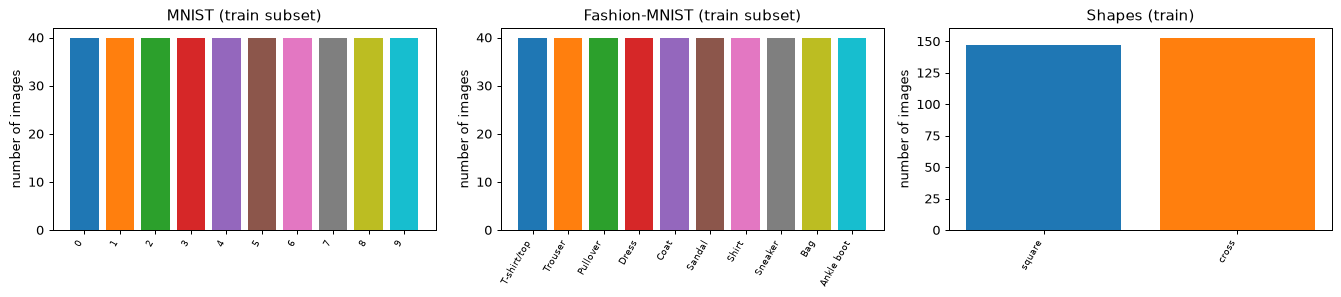

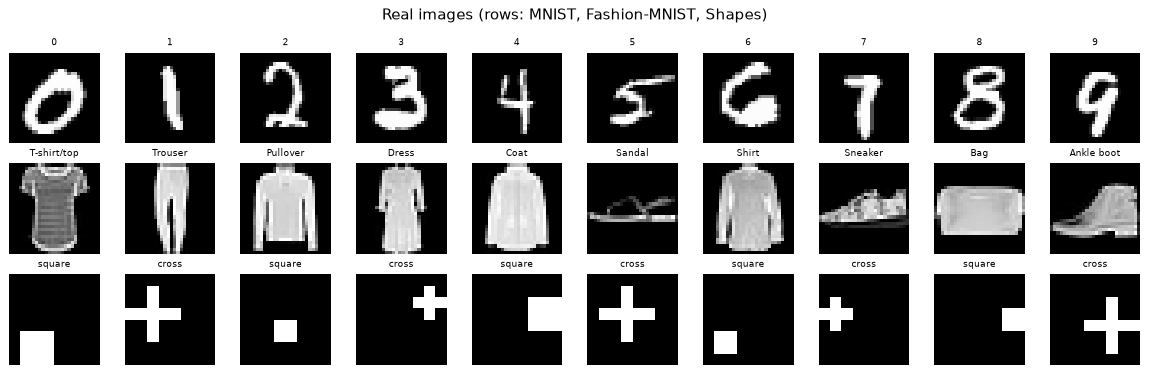

In [6]:
def describe(name, X, y, names, shape_img):
    print(f"=== {name} ===")
    print("  array shape:", tuple(X.shape), f"-> images of {shape_img[0]} x {shape_img[1]}, {X.shape[1]} features")
    fn = [f"pixel_{i}" for i in range(X.shape[1])]
    print("  feature names:", fn[:3], "...", fn[-2:], "(grey value in [0, 1])")
    print("  original label values:", sorted(set(y.tolist())), "->", [names[k] for k in sorted(set(y.tolist()))])
    print("  class counts:", dict(zip(sorted(set(y.tolist())), np.bincount(y.numpy()).tolist())))

for ds in DATASETS:
    describe(SPECS[ds]["title"] + " (training subset)", DATA[ds]["Xtr"], DATA[ds]["ytr"], SPECS[ds]["names"], (IMG, IMG))
describe("Shapes (training set)", SH["Xtr"], SH["ytr"], ["square", "cross"], (8, 8))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (title, y, names) in zip(axs, [(SPECS[d]["title"] + " (train subset)", DATA[d]["ytr"], SPECS[d]["names"]) for d in DATASETS] + [("Shapes (train)", SH["ytr"], ["square", "cross"])]):
    cnt = np.bincount(y.numpy()); ax.bar(range(len(cnt)), cnt, color=[plt.cm.tab10(k % 10) for k in range(len(cnt))])
    ax.set_xticks(range(len(cnt))); ax.set_xticklabels(names[:len(cnt)], rotation=60, ha="right", fontsize=7); ax.set_title(title); ax.set_ylabel("number of images")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(3, 10, figsize=(13, 4.2))
for r, ds in enumerate(DATASETS):
    for k in range(10):
        i = int((DATA[ds]["ytr"] == k).nonzero()[0, 0]); axs[r, k].imshow(DATA[ds]["Xtr"][i].reshape(IMG, IMG), cmap="gray"); axs[r, k].axis("off")
        axs[r, k].set_title(SPECS[ds]["names"][k], fontsize=7)
for k in range(10):
    i = int((SH["ytr"] == k % 2).nonzero()[k // 2, 0]); axs[2, k].imshow(SH["Xtr"][i].reshape(8, 8), cmap="gray"); axs[2, k].axis("off"); axs[2, k].set_title(["square", "cross"][k % 2], fontsize=7)
plt.suptitle("Real images (rows: MNIST, Fashion-MNIST, Shapes)"); plt.tight_layout(); plt.show()

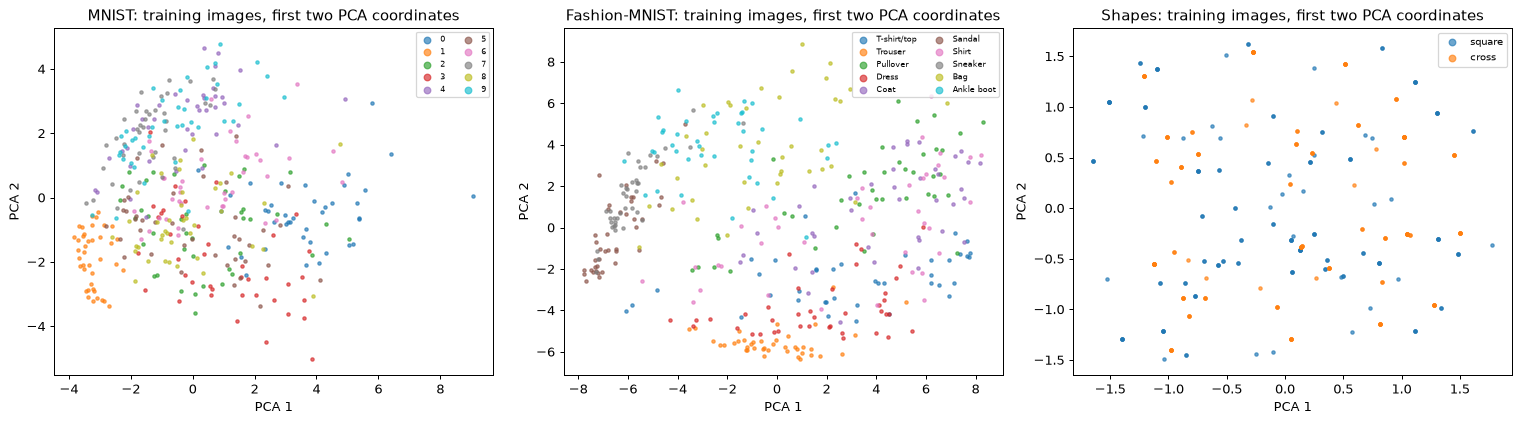

MNIST: explained variance of the two coordinates = 0.17
Fashion-MNIST: explained variance of the two coordinates = 0.48
Shapes: explained variance of the two coordinates = 0.26


In [7]:
# Scatter of the real observations in the first two PCA coordinates (PCA fitted on the training split), coloured by ground-truth label.
def pca_scatter(ax, Ztr, ytr, names, title):
    for k in np.unique(ytr):
        m = ytr == k; ax.scatter(Ztr[m, 0], Ztr[m, 1], s=7, alpha=0.65, color=plt.cm.tab10(int(k) % 10), label=names[int(k)])
    ax.set_title(title); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")

PCA2 = {}
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, ds in zip(axs[:2], DATASETS):
    p = PCA(n_components=2, random_state=SEED).fit(DATA[ds]["Xtr"].numpy()); PCA2[ds] = p
    pca_scatter(ax, p.transform(DATA[ds]["Xtr"].numpy()), DATA[ds]["ytr"].numpy(), SPECS[ds]["names"], f"{SPECS[ds]['title']}: training images, first two PCA coordinates")
    ax.legend(fontsize=6, ncol=2, markerscale=2)
p = PCA(n_components=2, random_state=SEED).fit(SH["Xtr"].numpy()); PCA2["shapes"] = p
pca_scatter(axs[2], p.transform(SH["Xtr"].numpy()), SH["ytr"].numpy(), ["square", "cross"], "Shapes: training images, first two PCA coordinates")
axs[2].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()
for ds in DATASETS:
    print(f"{SPECS[ds]['title']}: explained variance of the two coordinates = {PCA2[ds].explained_variance_ratio_.sum():.2f}")
print(f"Shapes: explained variance of the two coordinates = {PCA2['shapes'].explained_variance_ratio_.sum():.2f}")

## 2. Amplitude encoding (Eq. 1) and the exact preparation circuit

Neighbouring pixels are stored as real and imaginary part of one amplitude. The PennyLane convention is used throughout the simulator: qubit 0 is
the most significant bit of the basis-state index. Qiskit is little-endian, so a helper reverses the bit order when a state vector is handed to Qiskit.
The exact circuit is Qiskit's `StatePreparation`, transpiled to the basis `{cx, u}`. We verify that it really prepares the target state.

In [8]:
def amp_encode(X, nq):
    """Eq. (1): |psi(x)> = sum_j (x_{2j} + i x_{2j+1}) |j> / ||x||. X: [B, P] real -> [B, 2^nq] complex (zero padded). Differentiable."""
    B, P = X.shape; D = 2 ** nq
    buf = X.new_zeros(B, 2 * D); buf[:, :P] = X
    psi = torch.complex(buf[:, 0::2], buf[:, 1::2])
    return psi / psi.abs().pow(2).sum(1, keepdim=True).sqrt().clamp_min(1e-12)

def decode_image(psi, P):
    """Inverse of Eq. (1) up to the norm: the image that a (possibly approximate) state represents."""
    return torch.stack([psi.real, psi.imag], -1).reshape(psi.shape[0], -1)[:, :P]

def fidelity(a, b):
    return (a.conj() * b).sum(1).abs() ** 2

def to_qiskit_vec(psi, nq):
    """PennyLane ordering (qubit 0 = most significant) -> Qiskit ordering (qubit 0 = least significant)."""
    a = np.asarray(psi, dtype=np.complex128).reshape((2,) * nq)
    v = np.transpose(a, tuple(range(nq))[::-1]).reshape(-1)
    return v / np.linalg.norm(v)

def from_qiskit_vec(v, nq):
    return np.transpose(np.asarray(v).reshape((2,) * nq), tuple(range(nq))[::-1]).reshape(-1)

BASIS = ["cx", "u"]
def exact_circuit(psi, nq):
    """The paper's exact preparation (Qiskit's SBM routine) of one state."""
    qc = QuantumCircuit(nq, name="exact SBM")
    qc.append(StatePreparation(to_qiskit_vec(psi, nq)), range(nq))
    return qc

def transpile_basis(qc):
    return transpile(qc, basis_gates=BASIS, optimization_level=1, seed_transpiler=SEED)

def cost(qc):
    """CNOT count, depth and gate count after transpilation to {cx, u}; returns (dict, transpiled circuit)."""
    t = transpile_basis(qc); ops = t.count_ops()
    return dict(cx=int(ops.get("cx", 0)), depth=int(t.depth()), size=int(t.size())), t

# --- check on one MNIST test image ---
PSI_EX = {ds: amp_encode(DATA[ds]["Xte"], NQ) for ds in DATASETS}
psi0 = PSI_EX["mnist"][0]
t0 = time.time(); c0, tqc0 = cost(exact_circuit(psi0.numpy(), NQ)); dt = time.time() - t0
sv = from_qiskit_vec(Statevector(tqc0).data, NQ)
print(f"exact preparation of one 9-qubit MNIST state: {c0['cx']} CNOT, depth {c0['depth']}, {c0['size']} gates (transpile {dt:.1f} s)")
print("fidelity of the circuit's state with the target (must be 1):", float(abs(np.vdot(sv, psi0.numpy())) ** 2))
assert abs(np.vdot(sv, psi0.numpy())) ** 2 > 1 - 1e-5

exact preparation of one 9-qubit MNIST state: 502 CNOT, depth 1005, 1013 gates (transpile 4.4 s)
fidelity of the circuit's state with the target (must be 1): 1.0000000274740495


## 3. The approximate encoders

**MPS encoder.** Take the two-qubit reduced density matrix `rho` of a neighbouring pair, diagonalise it, and apply the unitary `U = sum_i |i><phi_i|` whose rows are
the eigenvectors sorted by decreasing eigenvalue. This moves as much weight as possible onto `|00>` of the pair. Doing this for the pairs (0,1), (2,3), (4,5),
(6,7) and then (1,2), (3,4), (5,6), (7,8) is one layer; after a few layers the state is close to `|0...0>`, and the weight on `|0...0>` after the layers is exactly
the fidelity of the encoder `D^dagger |0...0>` with the target (D = product of all U). Pairs inside a brick are disjoint, so processing them "in parallel" and
one after the other are the same. We stop at the first layer count that reaches 60 %.

**Variational encoder.** A circuit `V(theta)` of L layers (Rot gate on every qubit, then CNOT(0,1), CNOT(1,2), ..., CNOT(7,8)) is trained with Adam to maximise
`|<target|V|0>|^2`. All images of a chunk are optimised in parallel, each with its own parameters. If an image misses the target after 100 steps, a layer with small random
angles is appended (the old layers are kept as a warm start; CHOICE) and 100 more steps are run.

Both are written with batched PyTorch state-vector code and cross-checked against Qiskit circuits in section 5.

In [9]:
def rot_mats(a):
    """Matrices of qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) for angles a[..., 3] -> [..., 2, 2]."""
    phi, th, om = a[..., 0], a[..., 1], a[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda z: torch.polar(torch.ones_like(z), z)
    m00 = e(-(phi + om) / 2) * c; m01 = -e((phi - om) / 2) * s
    m10 = e(-(phi - om) / 2) * s; m11 = e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def groups_of(nq, gs=3):
    """Split the qubits into groups of at most gs consecutive qubits; (start, size) pairs. Fusing a group's rotations into one 2^g x 2^g matrix is 4x faster than gate by gate."""
    out, q = [], 0
    while q < nq:
        g = min(gs, nq - q); out.append((q, g)); q += g
    return out

def kron_group(Ug):
    """Ug [..., g, 2, 2] -> Kronecker product over the group [..., 2^g, 2^g] (first qubit of the group = most significant)."""
    M = Ug[..., 0, :, :]
    for j in range(1, Ug.shape[-3]):
        M = torch.einsum('...ij,...kl->...ikjl', M, Ug[..., j, :, :]).reshape(*M.shape[:-2], M.shape[-2] * 2, M.shape[-1] * 2)
    return M

def layer_mats(theta, nq):
    """Rotation layers for all L layers at once: theta [..., L, nq, 3] -> list over qubit groups of [..., L, 2^g, 2^g]."""
    U = rot_mats(theta)
    return [kron_group(U[..., q0:q0 + g, :, :]) for (q0, g) in groups_of(nq)]

def apply_group(psi, M, q0, g, nq):
    """Apply a fused gate M ([2^g,2^g] shared or [B,2^g,2^g] per sample) to the qubits q0..q0+g-1 of the batch of states psi [B, 2^nq]."""
    B = psi.shape[0]
    v = psi.reshape(B, 2 ** q0, 2 ** g, 2 ** (nq - q0 - g))
    return torch.einsum('ij,bajc->baic' if M.dim() == 2 else 'bij,bajc->baic', M, v).reshape(B, -1)
def chain_src(nq):
    """Index map of the CNOT chain CNOT(0,1), CNOT(1,2), ..., CNOT(nq-2, nq-1): new_state = old_state[src]."""
    idx = np.arange(2 ** nq); cur = idx.copy()
    for i in range(nq - 1):
        cbit = (idx >> (nq - 1 - i)) & 1
        cur = cur[idx ^ (cbit << (nq - 1 - (i + 1)))]
    return torch.as_tensor(cur, dtype=torch.long)

def zsigns(nq, ncls):
    """Rows = eigenvalues (+1/-1) of the class observables over the basis states: Z_0..Z_{nq-1} and, if ncls = nq + 1, the parity Z^(x)nq."""
    rows = [1 - 2 * ((torch.arange(2 ** nq) >> (nq - 1 - q)) & 1).float() for q in range(nq)]
    if ncls == nq + 1:                     # CHOICE: tenth class read out as the parity of all qubits
        rows.append(torch.stack(rows, 0).prod(0))
    return torch.stack(rows[:ncls], 0)

# ---------- variational encoder ----------
def var_state(theta, nq, SRC):
    """State V(theta)|0> for theta [B, L, nq, 3] (per-sample parameters)."""
    B, L = theta.shape[:2]
    psi = torch.zeros(B, 2 ** nq, dtype=CDT); psi[:, 0] = 1
    Ms = layer_mats(theta, nq); grp = groups_of(nq)
    for l in range(L):
        for gi, (q0, g) in enumerate(grp):
            psi = apply_group(psi, Ms[gi][:, l], q0, g, nq)
        psi = psi[:, SRC]
    return psi

def var_encode(target, nq, fid_target, steps, lr, max_layers, seed):
    """Variational approximate preparation. Returns prepared states, achieved fidelities, layers used, and the angles per image."""
    g = torch.Generator().manual_seed(seed); SRC = chain_src(nq)
    B = target.shape[0]; D = 2 ** nq
    prepared = torch.zeros(B, D, dtype=CDT); fid_final = torch.zeros(B); L_used = torch.zeros(B, dtype=torch.long); thetas = [None] * B
    active = torch.arange(B)
    theta = 0.1 * torch.randn(B, 1, nq, 3, generator=g)                  # CHOICE: small random start
    for L in range(1, max_layers + 1):
        theta = theta.detach().clone().requires_grad_(True)
        opt = torch.optim.Adam([theta], lr=lr); tgt = target[active]
        for s in range(steps):
            opt.zero_grad()
            fid = fidelity(tgt, var_state(theta, nq, SRC))
            (1 - fid).sum().backward(); opt.step()                        # images are independent: the sum is only for batching
        with torch.no_grad():
            psi = var_state(theta, nq, SRC); fid = fidelity(tgt, psi)
            done = (fid >= fid_target) | (L == max_layers)
            ia = active[done]
            prepared[ia] = psi[done]; fid_final[ia] = fid[done]; L_used[ia] = L
            for k, i in enumerate(ia.tolist()):
                thetas[i] = theta[done][k].detach().clone()
            keep = ~done
            if int(keep.sum()) == 0:
                break
            active = active[keep]
            theta = torch.cat([theta[keep].detach(), 0.1 * torch.randn(int(keep.sum()), 1, nq, 3, generator=g)], 1)
    return prepared, fid_final, L_used, thetas

# ---------- MPS encoder ----------
def pair_list(nq):
    return [(a, a + 1) for a in range(0, nq - 1, 2)] + [(a, a + 1) for a in range(1, nq - 1, 2)]

def apply2(psi, U, a, nq):
    B = psi.shape[0]
    v = psi.reshape(B, 2 ** a, 4, 2 ** (nq - a - 2))
    return torch.einsum('bij,bajc->baic', U, v).reshape(B, -1)

def reduced_pair(psi, a, nq):
    B = psi.shape[0]
    v = psi.reshape(B, 2 ** a, 4, 2 ** (nq - a - 2))
    return torch.einsum('baic,bajc->bij', v, v.conj())

def mps_encode(target, nq, fid_target, max_layers, keep_unitaries=False):
    """MPS-style approximate preparation. Returns prepared states, fidelities, layers used K, (optionally) the unitaries per layer/pair."""
    pairs = pair_list(nq); B = target.shape[0]; D = 2 ** nq
    cur = target; Us = []; fids = []
    for l in range(max_layers):
        layer = []
        for (a, _) in pairs:
            w, V = torch.linalg.eigh(reduced_pair(cur, a, nq))               # eigenvalues ascending
            U = V.flip(-1).conj().transpose(-1, -2).contiguous()             # rows = eigenvectors by decreasing eigenvalue
            cur = apply2(cur, U, a, nq); layer.append(U)
        Us.append(layer); fids.append(cur[:, 0].abs() ** 2)
    fids = torch.stack(fids, 1); ok = fids >= fid_target
    K = torch.where(ok.any(1), ok.float().argmax(1) + 1, torch.full((B,), max_layers))
    psi = torch.zeros(B, D, dtype=CDT); psi[:, 0] = 1
    eye = torch.eye(4, dtype=CDT).expand(B, 4, 4)
    for l in reversed(range(max_layers)):                                    # encoder = D^dagger |0>: undo the gates in reverse order
        act = (K > l)[:, None, None]
        for gi in reversed(range(len(pairs))):
            psi = apply2(psi, torch.where(act, Us[l][gi].conj().transpose(-1, -2), eye), pairs[gi][0], nq)
    return psi, fidelity(target, psi), K, (Us if keep_unitaries else None)

def encode_all(method, target, nq, fid_target, seed, chunk=ENC_CHUNK, keep=0):
    """Encode `target` in chunks. keep = number of leading images whose circuit data (unitaries / angles) is kept."""
    out = []; kept = None
    for s in range(0, target.shape[0], chunk):
        t = target[s:s + chunk]
        if method == "mps":
            psi, f, L, extra = mps_encode(t, nq, fid_target, MPS_MAX_LAYERS, keep_unitaries=(s == 0 and keep > 0))
        else:
            psi, f, L, extra = var_encode(t, nq, fid_target, ENC_STEPS, ENC_LR, ENC_MAX_LAYERS, seed + s)
        out.append((psi, f, L))
        if s == 0 and keep > 0:
            kept = extra
    psi, f, L = (torch.cat([o[i] for o in out]) for i in range(3))
    return psi, f, L, kept

In [10]:
# --- smoke test: both encoders on a few real MNIST test images ---
t0 = time.time(); pm, fm, Km, Um = mps_encode(PSI_EX["mnist"][:8], NQ, FID_TARGET, MPS_MAX_LAYERS, keep_unitaries=True); t_m = time.time() - t0
t0 = time.time(); pv, fv, Lv, thv = var_encode(PSI_EX["mnist"][:8], NQ, FID_TARGET, ENC_STEPS, ENC_LR, ENC_MAX_LAYERS, SEED); t_v = time.time() - t0
print(f"MPS        : fidelities {np.round(fm.numpy(), 2).tolist()}, layers {Km.tolist()}   ({t_m:.1f} s for 8 images)")
print(f"Variational: fidelities {np.round(fv.numpy(), 2).tolist()}, layers {Lv.tolist()}   ({t_v:.1f} s for 8 images)")
print("norms of the prepared states:", float(pm.abs().pow(2).sum(1).mean()), float(pv.abs().pow(2).sum(1).mean()))

MPS        : fidelities [0.5799999833106995, 0.6100000143051147, 0.6499999761581421, 0.6399999856948853, 0.6100000143051147, 0.6100000143051147, 0.6100000143051147, 0.6000000238418579], layers [12, 11, 9, 8, 6, 11, 11, 8]   (0.1 s for 8 images)
Variational: fidelities [0.6200000047683716, 0.6200000047683716, 0.6499999761581421, 0.6100000143051147, 0.6200000047683716, 0.6499999761581421, 0.6200000047683716, 0.6299999952316284], layers [10, 10, 8, 7, 8, 12, 9, 10]   (19.0 s for 8 images)
norms of the prepared states: 1.000001072883606 0.9999996423721313


## 4. Encode the whole datasets approximately

We encode training, validation and test images with both methods (target fidelity 60 %). The images attacked later are encoded again after the attack,
because an adversarial image is a new input that must go through the same approximate preparation.

In [11]:
ENC = {ds: {} for ds in DATASETS}
t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]
    d["psi_tr"], d["psi_va"], d["psi_te"] = amp_encode(d["Xtr"], NQ), amp_encode(d["Xva"], NQ), amp_encode(d["Xte"], NQ)
    sizes = [len(d["psi_te"]), len(d["psi_va"]), len(d["psi_tr"])]
    allpsi = torch.cat([d["psi_te"], d["psi_va"], d["psi_tr"]])                # test images first: their circuit data is kept for section 6
    for method in ("mps", "var"):
        psi, f, L, kept = encode_all(method, allpsi, NQ, FID_TARGET, SEED, keep=N_DEPTH)
        e = {}
        for sp, (a, b) in zip(("te", "va", "tr"), [(0, sizes[0]), (sizes[0], sizes[0] + sizes[1]), (sizes[0] + sizes[1], sum(sizes))]):
            e[sp] = dict(psi=psi[a:b], fid=f[a:b], L=L[a:b], kept=(kept if sp == "te" else None))
        ENC[ds][method] = e
        print(f"{SPECS[ds]['title']:14s} {method:3s}: mean fidelity train {float(e['tr']['fid'].mean()):.3f} / test {float(e['te']['fid'].mean()):.3f} "
              f"(min {float(e['te']['fid'].min()):.2f}), mean layers {float(e['tr']['L'].float().mean()):.2f}, images that missed the target {int((e['tr']['fid'] < FID_TARGET).sum())}   [{time.time() - t0:.0f} s elapsed]")

MNIST          mps: mean fidelity train 0.613 / test 0.613 (min 0.49), mean layers 8.81, images that missed the target 47   [2 s elapsed]


MNIST          var: mean fidelity train 0.623 / test 0.621 (min 0.60), mean layers 8.48, images that missed the target 0   [154 s elapsed]


Fashion-MNIST  mps: mean fidelity train 0.671 / test 0.669 (min 0.60), mean layers 3.04, images that missed the target 1   [156 s elapsed]


Fashion-MNIST  var: mean fidelity train 0.638 / test 0.640 (min 0.60), mean layers 4.10, images that missed the target 0   [213 s elapsed]


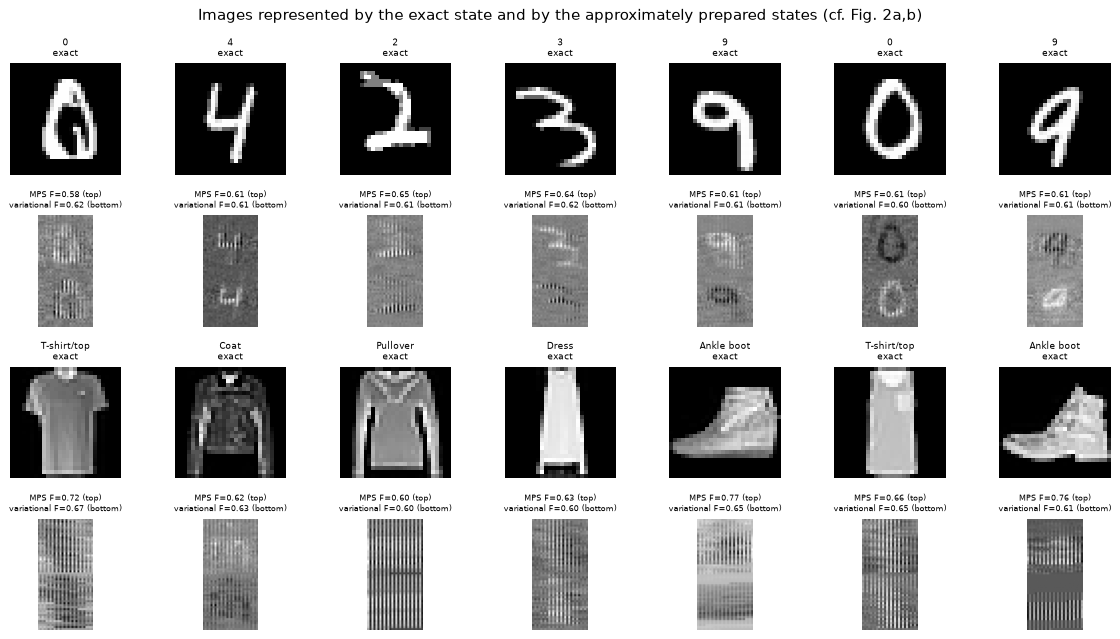

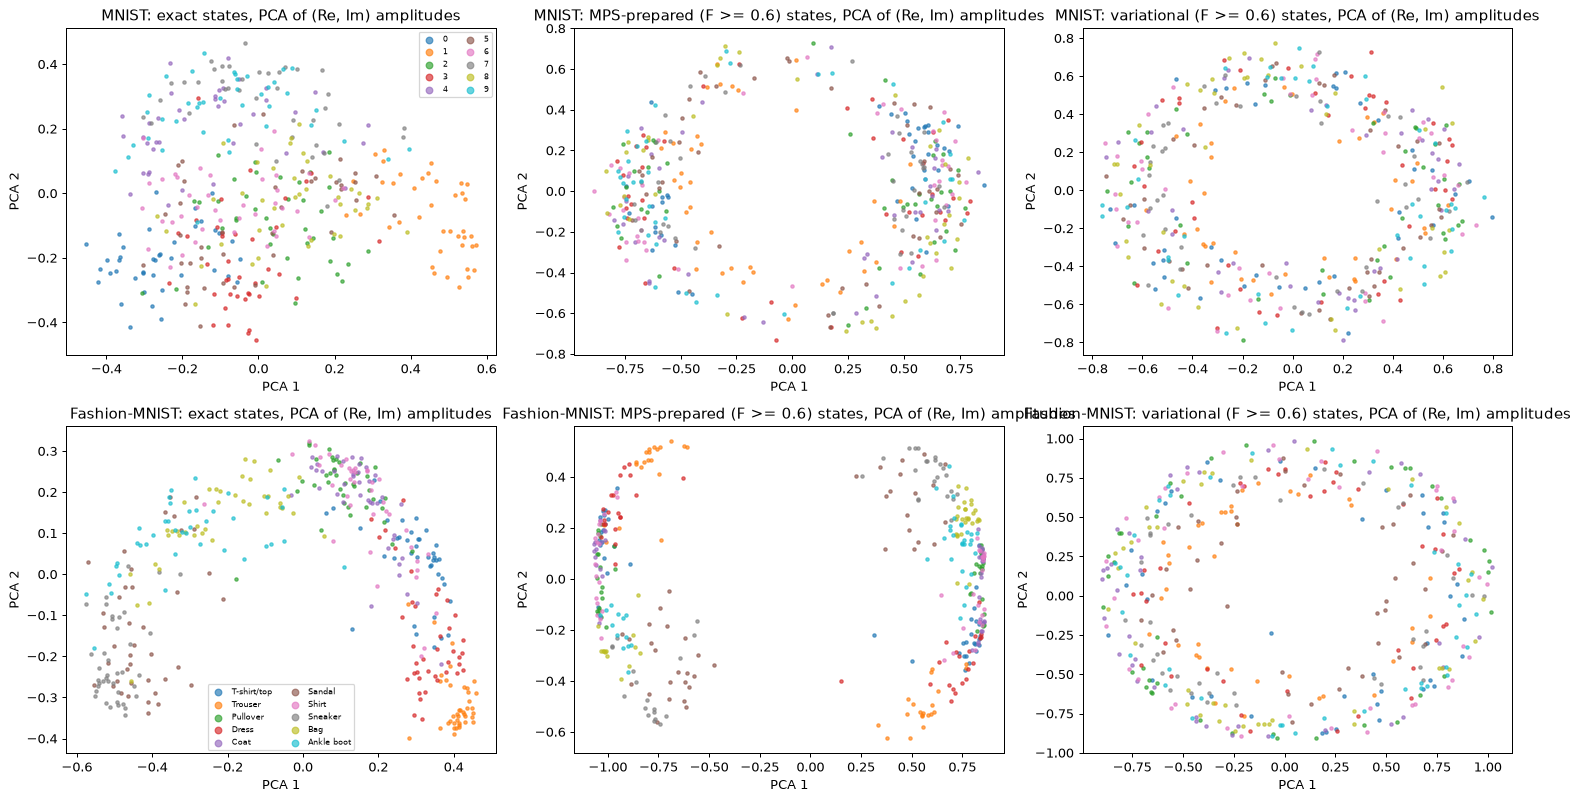

In [12]:
# Fig. 2a/b analogue: the image that the prepared state represents (Eq. 1 read backwards) for a clean test image.
fig, axs = plt.subplots(4, 7, figsize=(13, 7.2))
for r, ds in enumerate(DATASETS):
    for c in range(7):
        i = c
        im_t = decode_image(PSI_EX[ds][i:i + 1], IMG * IMG)[0].reshape(IMG, IMG)
        im_m = decode_image(ENC[ds]["mps"]["te"]["psi"][i:i + 1], IMG * IMG)[0].reshape(IMG, IMG); im_v = decode_image(ENC[ds]["var"]["te"]["psi"][i:i + 1], IMG * IMG)[0].reshape(IMG, IMG)
        axs[2 * r, c].imshow(im_t, cmap="gray"); axs[2 * r, c].axis("off"); axs[2 * r, c].set_title(f"{SPECS[ds]['names'][int(DATA[ds]['yte'][i])]}\nexact", fontsize=7)
        axs[2 * r + 1, c].imshow(np.vstack([im_m, im_v]), cmap="gray"); axs[2 * r + 1, c].axis("off")
        axs[2 * r + 1, c].set_title(f"MPS F={float(ENC[ds]['mps']['te']['fid'][i]):.2f} (top)\nvariational F={float(ENC[ds]['var']['te']['fid'][i]):.2f} (bottom)", fontsize=6)
plt.suptitle("Images represented by the exact state and by the approximately prepared states (cf. Fig. 2a,b)"); plt.tight_layout(); plt.show()

# Labelled 2-D projection of the approximately prepared training states (real images, ground-truth classes).
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
for r, ds in enumerate(DATASETS):
    ytr = DATA[ds]["ytr"].numpy()
    for c, (lab, psi) in enumerate([("exact", DATA[ds]["psi_tr"]), ("MPS-prepared (F >= 0.6)", ENC[ds]["mps"]["tr"]["psi"]), ("variational (F >= 0.6)", ENC[ds]["var"]["tr"]["psi"])]):
        feats = torch.cat([psi.real, psi.imag], 1).numpy()
        Z = PCA(n_components=2, random_state=SEED).fit(feats).transform(feats)
        pca_scatter(axs[r, c], Z, ytr, SPECS[ds]["names"], f"{SPECS[ds]['title']}: {lab} states, PCA of (Re, Im) amplitudes")
        if c == 0: axs[r, c].legend(fontsize=6, ncol=2, markerscale=2)
plt.tight_layout(); plt.show()

## 5. The quantum variational classifier (QVC) and its training

After the encoding comes `U(theta)`: L layers, each with one arbitrary rotation `Rot(phi, theta, omega)` per qubit followed by the CNOT chain
`CNOT(0,1) ... CNOT(7,8)`. The class scores are the expectation values of Pauli-Z on the qubits (class 9: the parity of all nine qubits, a CHOICE), a softmax turns them into
probabilities (Eq. 6) and the cross-entropy (Eq. 7) is minimised with Adam. One model is trained **per encoding**, on the training images prepared with that encoder
and tested on test images prepared with the same encoder (the paper's protocol). The simulator is a batched PyTorch state-vector code; in section 6 it is checked against a PennyLane QNode and a Qiskit circuit.

Random seeds fix the initial angles and the batch order; the encoders use `SEED` as well.

In [13]:
class QVC(nn.Module):
    """L x [Rot on every qubit, CNOT chain]; outputs <Z_j> for the class observables. Input: batch of states [B, 2^nq]."""
    def __init__(self, nq, L, ncls, seed, init_std=INIT_STD):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.nq, self.L = nq, L
        self.theta = nn.Parameter(init_std * torch.randn(L, nq, 3, generator=g))
        self.register_buffer("src", chain_src(nq)); self.register_buffer("zs", zsigns(nq, ncls))
    def forward(self, psi):
        Ms = layer_mats(self.theta, self.nq); grp = groups_of(self.nq)       # fused rotation layers, shared by the whole batch
        for l in range(self.L):
            for gi, (q0, g) in enumerate(grp):
                psi = apply_group(psi, Ms[gi][l], q0, g, self.nq)
            psi = psi[:, self.src]
        return (psi.abs() ** 2) @ self.zs.T

@torch.no_grad()
def predict(model, psi, bs=500):
    return torch.cat([model(psi[i:i + bs]) for i in range(0, psi.shape[0], bs)])

def acc_of(model, psi, y):
    return float((predict(model, psi).argmax(1) == y).float().mean())

def train_qvc(psi_tr, y_tr, psi_va, y_va, seed, nq, L, ncls, epochs, batch, lr):
    torch.manual_seed(seed)
    model = QVC(nq, L, ncls, seed); opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed); hist = []
    for ep in range(epochs):
        perm = torch.randperm(psi_tr.shape[0], generator=g)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(psi_tr[idx]), y_tr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(acc_of(model, psi_va, y_va))
    return model, hist

SRC_SIZE = sum(p.numel() for p in QVC(NQ, QVC_LAYERS, N_CLASSES, 0).parameters())
print(f"QVC: {NQ} qubits, {QVC_LAYERS} layers, {SRC_SIZE} trainable angles (3 per qubit and layer)")

QVC: 9 qubits, 8 layers, 216 trainable angles (3 per qubit and layer)


MNIST          exact: test accuracy 66.0 +- 0.0 %   (final validation 58.3 %)   [20 s elapsed]


MNIST          mps  : test accuracy 61.0 +- 0.0 %   (final validation 51.7 %)   [36 s elapsed]


MNIST          var  : test accuracy 54.0 +- 0.0 %   (final validation 56.7 %)   [52 s elapsed]


Fashion-MNIST  exact: test accuracy 45.0 +- 0.0 %   (final validation 50.0 %)   [71 s elapsed]


Fashion-MNIST  mps  : test accuracy 38.0 +- 0.0 %   (final validation 38.3 %)   [88 s elapsed]


Fashion-MNIST  var  : test accuracy 40.0 +- 0.0 %   (final validation 26.7 %)   [105 s elapsed]


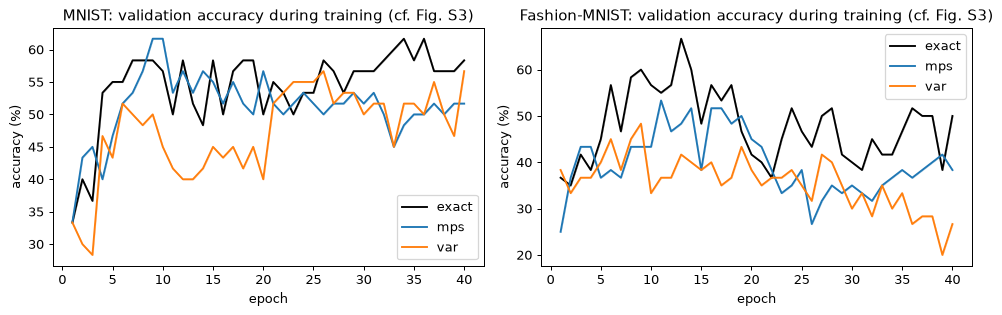

In [14]:
MODELS = {ds: {} for ds in DATASETS}; HIST = {ds: {} for ds in DATASETS}; CLEAN = {ds: {} for ds in DATASETS}
def split_psi(ds, method, sp):
    if method == "exact": return DATA[ds]["psi_" + sp]
    return ENC[ds][method][sp]["psi"]

t0 = time.time()
for ds in DATASETS:
    for method in ("exact", "mps", "var"):
        MODELS[ds][method], HIST[ds][method], CLEAN[ds][method] = [], [], []
        for s in range(N_SEEDS):
            m, h = train_qvc(split_psi(ds, method, "tr"), DATA[ds]["ytr"], split_psi(ds, method, "va"), DATA[ds]["yva"], SEED + s, NQ, QVC_LAYERS, N_CLASSES, EPOCHS, BATCH, LR_QVC)
            MODELS[ds][method].append(m); HIST[ds][method].append(h)
            CLEAN[ds][method].append(acc_of(m, split_psi(ds, method, "te"), DATA[ds]["yte"]))
        print(f"{SPECS[ds]['title']:14s} {method:5s}: test accuracy {100 * np.mean(CLEAN[ds][method]):.1f} +- {100 * np.std(CLEAN[ds][method]):.1f} %   (final validation {100 * np.mean([h[-1] for h in HIST[ds][method]]):.1f} %)   [{time.time() - t0:.0f} s elapsed]")

fig, axs = plt.subplots(1, len(DATASETS), figsize=(11, 3.6))
for ax, ds in zip(axs, DATASETS):
    for method, col in zip(("exact", "mps", "var"), ("k", "tab:blue", "tab:orange")):
        H = 100 * np.array(HIST[ds][method]); ax.plot(range(1, EPOCHS + 1), H.mean(0), color=col, label=method)
        ax.fill_between(range(1, EPOCHS + 1), H.mean(0) - H.std(0), H.mean(0) + H.std(0), color=col, alpha=0.2)
    ax.set_title(f"{SPECS[ds]['title']}: validation accuracy during training (cf. Fig. S3)"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy (%)"); ax.legend()
plt.tight_layout(); plt.show()

### Classical baselines on exactly the same inputs

A support-vector machine (RBF) and a random forest are trained on the very vectors the QVC receives (real and imaginary parts of the prepared state, 1 024 numbers),
separately for the exact, MPS and variational preparations. They show whether the *approximate states* still carry the class information, independently of the quantum classifier.

In [15]:
BASE = {ds: {} for ds in DATASETS}
def feats(psi): return torch.cat([psi.real, psi.imag], 1).numpy()
for ds in DATASETS:
    for method in ("exact", "mps", "var"):
        Xa, Xb = feats(split_psi(ds, method, "tr")), feats(split_psi(ds, method, "te"))
        svc = SVC(kernel="rbf", C=10, gamma="scale").fit(Xa, DATA[ds]["ytr"].numpy())            # CHOICE: C = 10
        rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2).fit(Xa, DATA[ds]["ytr"].numpy())
        BASE[ds][method] = dict(svc=svc, rf=rf, acc_svc=float(svc.score(Xb, DATA[ds]["yte"].numpy())), acc_rf=float(rf.score(Xb, DATA[ds]["yte"].numpy())))
rows = []
for ds in DATASETS:
    for method in ("exact", "mps", "var"):
        rows.append(dict(dataset=SPECS[ds]["title"], encoding=method, QVC=f"{100 * np.mean(CLEAN[ds][method]):.1f} +- {100 * np.std(CLEAN[ds][method]):.1f}",
                         SVC_rbf=f"{100 * BASE[ds][method]['acc_svc']:.1f}", RandomForest=f"{100 * BASE[ds][method]['acc_rf']:.1f}",
                         mean_state_fidelity=f"{float(torch.mean(fidelity(DATA[ds]['psi_te'], split_psi(ds, method, 'te')))):.3f}"))
CLEAN_TABLE = pd.DataFrame(rows); display(CLEAN_TABLE)

,dataset,encoding,QVC,SVC_rbf,RandomForest,mean_state_fidelity
0,MNIST,exact,66.0 +- 0.0,94.0,90.0,1.000
1,MNIST,mps,61.0 +- 0.0,71.0,61.0,0.613
2,MNIST,var,54.0 +- 0.0,72.0,54.0,0.621
3,Fashion-MNIST,exact,45.0 +- 0.0,72.0,71.0,1.000
4,Fashion-MNIST,mps,38.0 +- 0.0,61.0,57.0,0.669
5,Fashion-MNIST,var,40.0 +- 0.0,57.0,54.0,0.640


## Quantum Circuit Architecture

Every circuit below is *the object that is executed*, built as a Qiskit circuit (encoders) or a PennyLane QNode (classifier), and each is checked against the
PyTorch simulator that produced the numbers in this notebook:

* exact encoder: `StatePreparation` of one MNIST test image, drawn one level unrolled; the fully transpiled `{cx, u}` version is counted;
* MPS encoder: the circuit `D^dagger` for one image (two-qubit unitaries drawn as boxes, then synthesised into CNOTs and counted);
* variational encoder: the layered circuit with the angles found for that image;
* the QVC: the PennyLane QNode (`StatePrep`, `Rot`, `CNOT`, Pauli-Z measurements), plus its Qiskit twin used in the noise study.

Assumptions where the paper omits details: the position of the CNOT chain inside a layer (after the rotations, as in the text), the parity read-out of class 9, the number of layers
(see configuration) and `Rot` instead of separate RX/RY/RZ (identical up to parametrisation).

In [16]:
def mps_circuit(Us, K, i, nq):
    """Circuit D^dagger for image i: undo the disentangling unitaries in reverse order. Qiskit qubit order [a+1, a] matches our pair basis |s_a s_{a+1}>."""
    qc = QuantumCircuit(nq, name="MPS encoder"); pairs = pair_list(nq)
    for l in reversed(range(K)):
        for gi in reversed(range(len(pairs))):
            a = pairs[gi][0]; W = Us[l][gi][i].conj().T.numpy().astype(np.complex128)
            u_, _, vh_ = np.linalg.svd(W); W = u_ @ vh_                         # float32 eigenvectors -> exactly unitary (change ~1e-7)
            qc.unitary(W, [a + 1, a], label=f"U{l + 1}.{gi + 1}^+")
    return qc

def rot_gates(qc, ang, q):
    qc.rz(float(ang[0]), q); qc.ry(float(ang[1]), q); qc.rz(float(ang[2]), q)      # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)

def var_circuit(theta, nq):
    qc = QuantumCircuit(nq, name="variational encoder")
    for l in range(theta.shape[0]):
        for q in range(nq): rot_gates(qc, theta[l, q], q)
        for q in range(nq - 1): qc.cx(q, q + 1)
    return qc

def qvc_circuit(theta, nq):
    qc = QuantumCircuit(nq, name="QVC")
    for l in range(theta.shape[0]):
        for q in range(nq): rot_gates(qc, theta[l, q], q)
        for q in range(nq - 1): qc.cx(q, q + 1)
    return qc

def show(qc, title, **kw):
    """Draw a Qiskit circuit with matplotlib and put a title on it."""
    fig = qc.draw("mpl", **kw); fig.suptitle(title, fontsize=11, y=1.0); display(fig); plt.close(fig)

def excerpt(tq, n):
    """First n instructions of a transpiled circuit (to look at real gates of a circuit that is too long to draw)."""
    part = QuantumCircuit(tq.num_qubits)
    for ins in tq.data[:n]:
        part.append(ins.operation, [tq.find_bit(q).index for q in ins.qubits])
    return part

def sv_fidelity(qc, target_psi, nq):
    return float(abs(np.vdot(from_qiskit_vec(Statevector(qc).data, nq), np.asarray(target_psi, dtype=np.complex128))) ** 2)

ds0 = "mnist"; I0 = 0
e_m, e_v = ENC[ds0]["mps"]["te"], ENC[ds0]["var"]["te"]
qc_ex = exact_circuit(PSI_EX[ds0][I0].numpy(), NQ)
qc_mps = mps_circuit(e_m["kept"], int(e_m["L"][I0]), I0, NQ)
qc_var = var_circuit(e_v["kept"][I0].numpy(), NQ)
rows = []
for name, qc, target_f in [("exact (SBM)", qc_ex, 1.0), ("MPS", qc_mps, float(e_m["fid"][I0])), ("variational", qc_var, float(e_v["fid"][I0]))]:
    c, tq = cost(qc)
    f = sv_fidelity(tq, PSI_EX[ds0][I0].numpy(), NQ)
    rows.append(dict(encoder=name, qubits=NQ, cx_after_transpile=c["cx"], depth_after_transpile=c["depth"], gates=c["size"], fidelity_of_circuit=round(f, 4), fidelity_from_simulator=round(target_f, 4)))
    assert abs(f - target_f) < 2e-3, f"{name}: Qiskit circuit disagrees with the PyTorch encoder ({f} vs {target_f})"
print("Encoding circuits for one MNIST test image (circuit fidelity from Qiskit == fidelity from the simulator):")
display(pd.DataFrame(rows))

Encoding circuits for one MNIST test image (circuit fidelity from Qiskit == fidelity from the simulator):


,encoder,qubits,cx_after_transpile,depth_after_transpile,gates,fidelity_of_circuit,fidelity_from_simulator
0,exact (SBM),9,502,1005,1013,1.0000,1.0000
1,MPS,9,288,145,873,0.5767,0.5767
2,variational,9,80,36,170,0.6243,0.6243


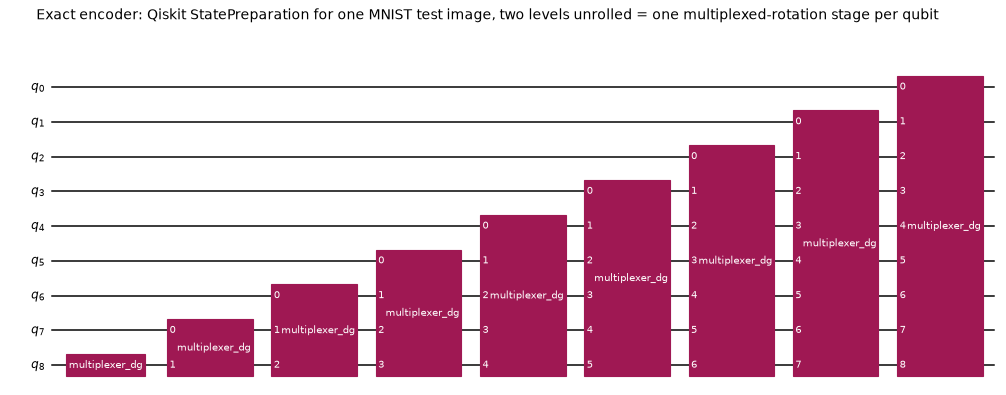

full exact circuit after transpilation to {cx, u}: {'cx': 502, 'depth': 1005, 'size': 1013}


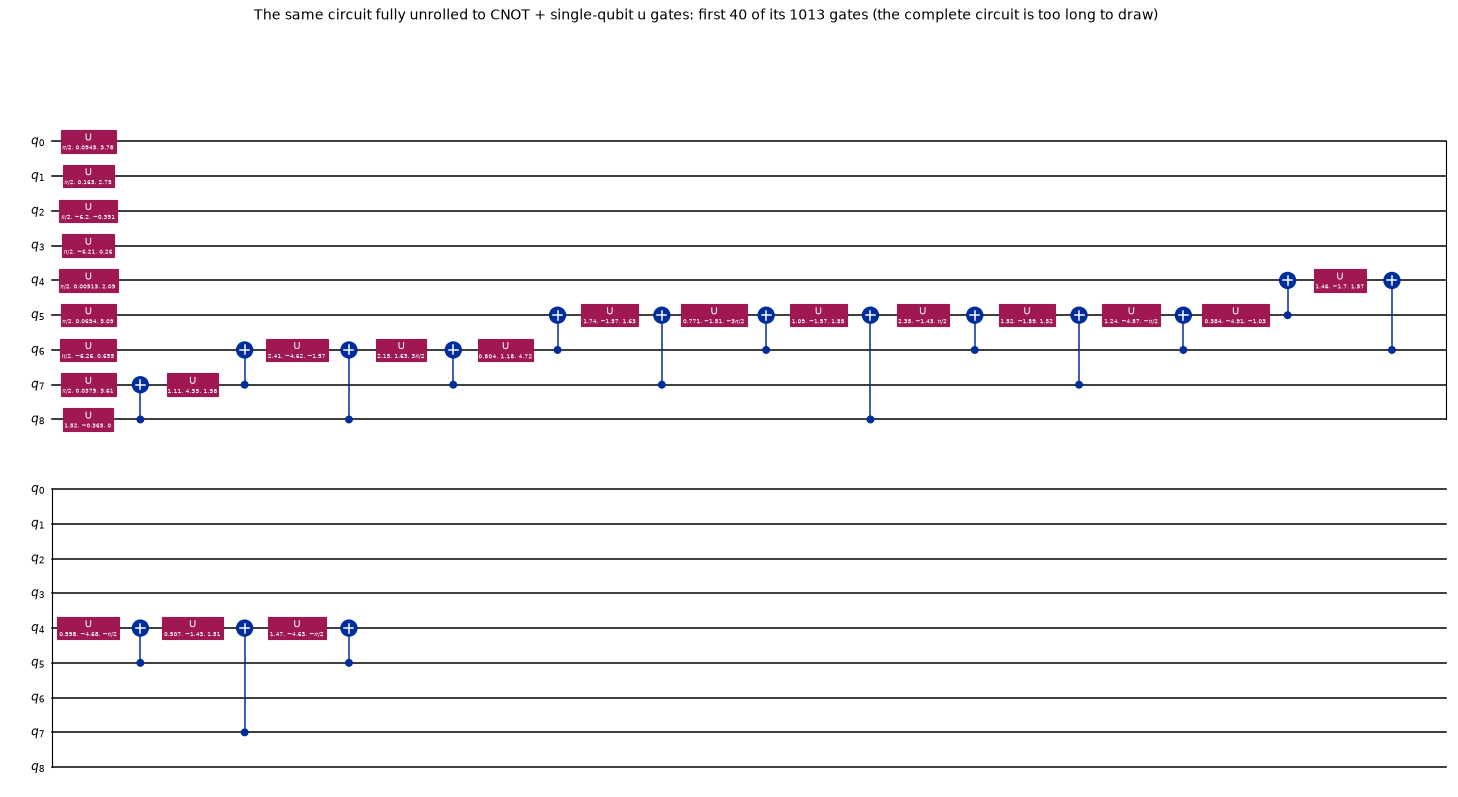

In [17]:
c_ex, tq_ex = cost(qc_ex)
show(qc_ex.decompose(reps=2), "Exact encoder: Qiskit StatePreparation for one MNIST test image, two levels unrolled = one multiplexed-rotation stage per qubit", fold=40, scale=0.6)
print("full exact circuit after transpilation to {cx, u}:", c_ex)
show(excerpt(tq_ex, 40), f"The same circuit fully unrolled to CNOT + single-qubit u gates: first 40 of its {c_ex['size']} gates (the complete circuit is too long to draw)", fold=40, scale=0.6)

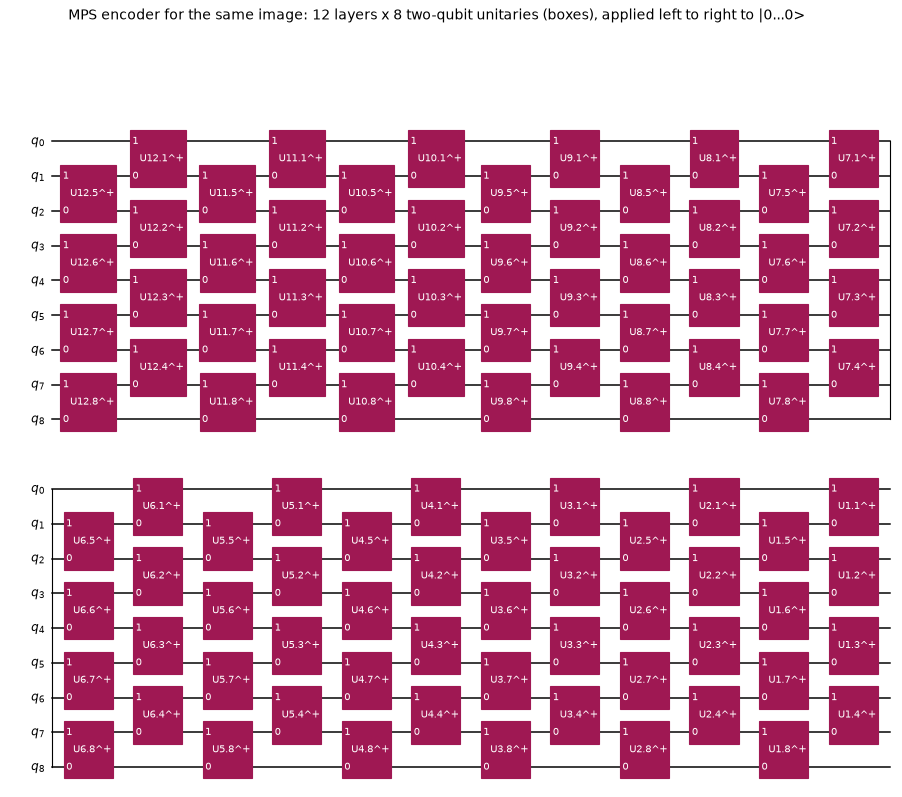

MPS circuit after transpilation to {cx, u}: {'cx': 288, 'depth': 145, 'size': 873} | two-qubit unitaries: 96


In [18]:
show(qc_mps, f"MPS encoder for the same image: {int(e_m['L'][I0])} layers x 8 two-qubit unitaries (boxes), applied left to right to |0...0>", fold=24, scale=0.6)
print("MPS circuit after transpilation to {cx, u}:", cost(qc_mps)[0], "| two-qubit unitaries:", qc_mps.size())

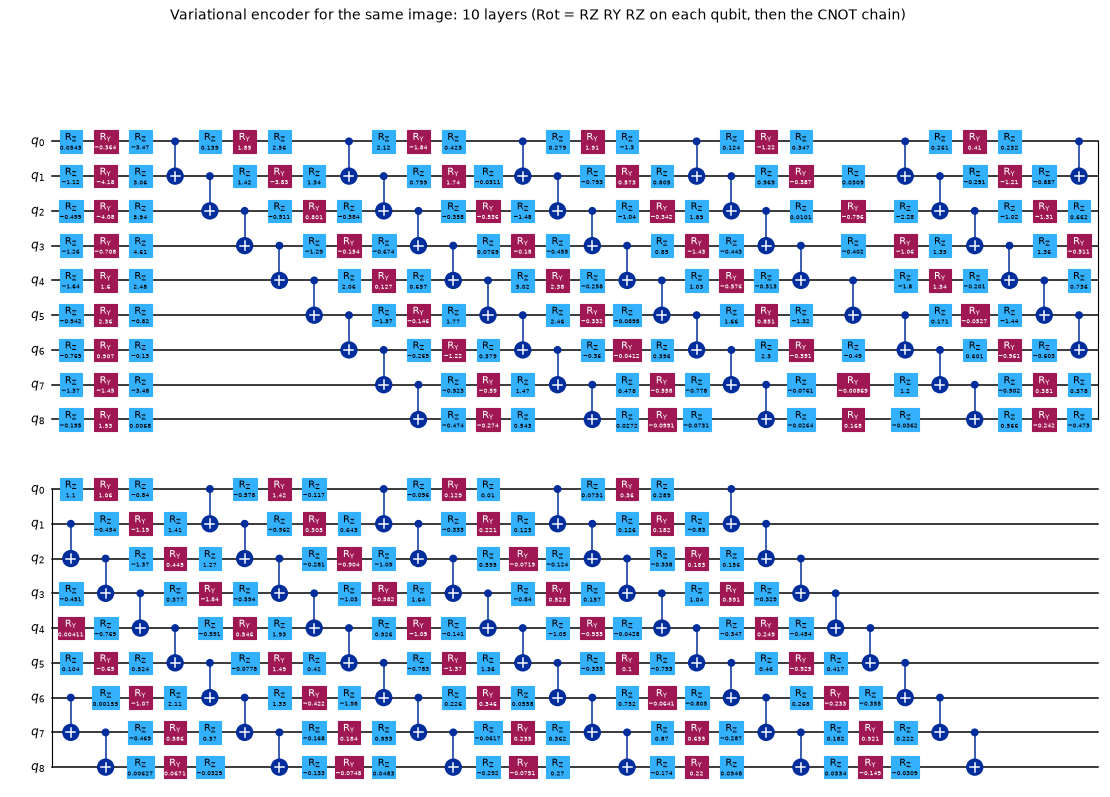

variational circuit: {'cx': 80, 'depth': 36, 'size': 170} | trainable angles: 270


In [19]:
show(qc_var, f"Variational encoder for the same image: {int(e_v['L'][I0])} layers (Rot = RZ RY RZ on each qubit, then the CNOT chain)", fold=30, scale=0.6)
print("variational circuit:", cost(qc_var)[0], "| trainable angles:", int(e_v["kept"][I0].numel()))

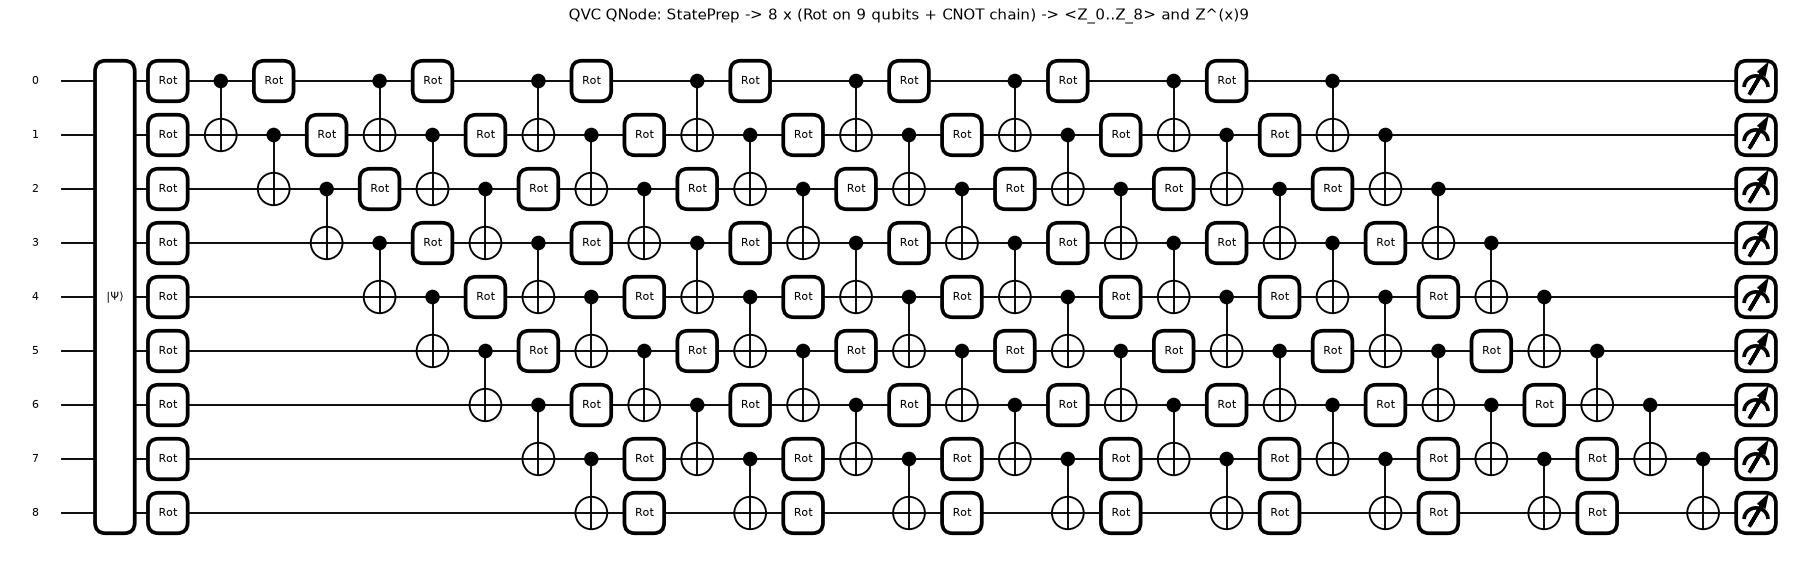

QVC qubits: 9 | trainable angles: 216 | CNOTs in the classifier: 64 | depth of its Qiskit twin after merging rotations: 30


In [20]:
# The QVC as a PennyLane QNode (what the notebook trains), drawn from the real QNode with the trained angles of the exact-encoding model.
dev = qml.device("default.qubit", wires=NQ)
Zs = [qml.Z(j) for j in range(NQ)]
@qml.qnode(dev, interface="torch", diff_method="backprop")
def qvc_qnode(psi, theta):
    qml.StatePrep(psi, wires=range(NQ), normalize=True)                       # the encoded input state (exact or approximate)
    for l in range(theta.shape[0]):
        for q in range(NQ):
            qml.Rot(theta[l, q, 0], theta[l, q, 1], theta[l, q, 2], wires=q)
        for q in range(NQ - 1):
            qml.CNOT(wires=[q, q + 1])
    return [qml.expval(z) for z in Zs] + [qml.expval(functools.reduce(lambda a, b: a @ b, Zs))]

mq = MODELS[ds0]["exact"][0]
th = mq.theta.detach().double()
fig, ax = qml.draw_mpl(qvc_qnode, decimals=None, fontsize=9)(PSI_EX[ds0][I0].to(torch.complex128), th)
fig.set_size_inches(min(40, 2.0 * QVC_LAYERS + 4), 6); plt.title(f"QVC QNode: StatePrep -> {QVC_LAYERS} x (Rot on 9 qubits + CNOT chain) -> <Z_0..Z_8> and Z^(x)9"); plt.show()
print("QVC qubits:", NQ, "| trainable angles:", int(th.numel()), "| CNOTs in the classifier:", QVC_LAYERS * (NQ - 1),
      "| depth of its Qiskit twin after merging rotations:", transpile_basis(qvc_circuit(th.numpy(), NQ)).depth())

In [21]:
# Equivalence: PyTorch simulator == PennyLane QNode == Qiskit circuit (exact encoder circuit followed by the QVC circuit).
x_in = PSI_EX[ds0][:3]
ours = mq(x_in).detach().double()
ref = torch.stack([torch.stack(qvc_qnode(x_in[i].to(torch.complex128), th)) for i in range(3)])
print("max |PyTorch - PennyLane| over 3 images x 10 outputs:", float((ours - ref).abs().max()))
assert float((ours - ref).abs().max()) < 1e-4

def zexp_from_probs(p, nq, ncls):
    k = np.arange(2 ** nq); s = [1 - 2 * ((k >> q) & 1) for q in range(nq)]          # Qiskit: qubit q = bit q of the index
    if ncls == nq + 1: s.append(np.prod(s, 0))
    return np.array(s[:ncls]) @ p

qk = mq.theta.detach().numpy()
full = transpile_basis(exact_circuit(x_in[0].numpy(), NQ)).compose(qvc_circuit(qk, NQ))
z_q = zexp_from_probs(Statevector(full).probabilities(), NQ, N_CLASSES)
print("max |PyTorch - Qiskit (encoder + QVC circuit)|:", float(np.abs(z_q - ours[0].numpy()).max()))
assert float(np.abs(z_q - ours[0].numpy()).max()) < 1e-3
print(f"Executed architecture: {NQ} qubits | exact encoder {cost(qc_ex)[0]['cx']} CNOT, depth {cost(qc_ex)[0]['depth']} | QVC {QVC_LAYERS} layers, {int(th.numel())} parameters")

max |PyTorch - PennyLane| over 3 images x 10 outputs: 1.0907064074139328e-07


max |PyTorch - Qiskit (encoder + QVC circuit)|: 6.39354122422553e-08


Executed architecture: 9 qubits | exact encoder 502 CNOT, depth 1005 | QVC 8 layers, 216 parameters


## 6. Circuit depth and CNOT count: exact versus approximate (claim C1, Fig. 1d)

For `N_DEPTH` test images per dataset we build the exact circuit and the two approximate circuits with Qiskit, transpile them to `{cx, u}`, and count CNOTs and depth.
All encoders aim at a fidelity of 60 %. The paper's claim: the approximate circuits need about **two orders of magnitude fewer** entangling gates.

MNIST: circuits built and transpiled  [6 s elapsed]


Fashion-MNIST: circuits built and transpiled  [11 s elapsed]


,dataset,encoder,images,mean_fidelity,mean_CNOT,median_CNOT,mean_depth,CNOT_reduction_vs_exact
0,MNIST,exact,10,1.000,502.0,502.0,1005.0,1.0
1,MNIST,mps,10,0.609,227.9,240.0,115.0,2.2
2,MNIST,var,10,0.617,72.8,72.0,33.3,6.9
3,Fashion-MNIST,exact,10,1.000,502.0,502.0,1005.0,1.0
4,Fashion-MNIST,mps,10,0.668,84.0,84.0,43.0,6.0
5,Fashion-MNIST,var,10,0.630,40.8,48.0,21.3,12.3


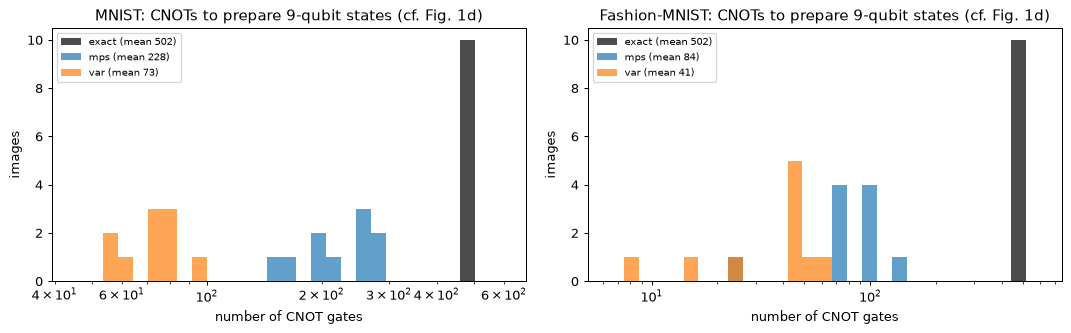

In [22]:
CIRCS = {ds: {m: [] for m in ("exact", "mps", "var")} for ds in DATASETS}; DEPTH = {ds: {} for ds in DATASETS}
t0 = time.time()
for ds in DATASETS:
    e_m, e_v = ENC[ds]["mps"]["te"], ENC[ds]["var"]["te"]
    for m in ("exact", "mps", "var"):
        cx, dp, sz = [], [], []
        for i in range(N_DEPTH):
            qc = {"exact": lambda: exact_circuit(PSI_EX[ds][i].numpy(), NQ), "mps": lambda: mps_circuit(e_m["kept"], int(e_m["L"][i]), i, NQ),
                  "var": lambda: var_circuit(e_v["kept"][i].numpy(), NQ)}[m]()
            c, tq = cost(qc); cx.append(c["cx"]); dp.append(c["depth"]); sz.append(c["size"]); CIRCS[ds][m].append(tq)
        DEPTH[ds][m] = dict(cx=np.array(cx), depth=np.array(dp), size=np.array(sz))
    print(f"{SPECS[ds]['title']}: circuits built and transpiled  [{time.time() - t0:.0f} s elapsed]")
    # consistency: the Qiskit circuits reproduce the simulator's states
    for m, key in (("mps", e_m), ("var", e_v)):
        f_circ = np.array([sv_fidelity(CIRCS[ds][m][i], PSI_EX[ds][i].numpy(), NQ) for i in range(min(N_DEPTH, 5))])
        assert np.allclose(f_circ, key["fid"][:len(f_circ)].numpy(), atol=2e-3), (m, f_circ, key["fid"][:len(f_circ)])

rows = []
for ds in DATASETS:
    for m in ("exact", "mps", "var"):
        d = DEPTH[ds][m]; f = {"exact": 1.0, "mps": float(ENC[ds]["mps"]["te"]["fid"][:N_DEPTH].mean()), "var": float(ENC[ds]["var"]["te"]["fid"][:N_DEPTH].mean())}[m]
        rows.append(dict(dataset=SPECS[ds]["title"], encoder=m, images=N_DEPTH, mean_fidelity=round(f, 3), mean_CNOT=round(d["cx"].mean(), 1), median_CNOT=float(np.median(d["cx"])),
                         mean_depth=round(d["depth"].mean(), 1), CNOT_reduction_vs_exact=round(DEPTH[ds]["exact"]["cx"].mean() / d["cx"].mean(), 1)))
DEPTH_TABLE = pd.DataFrame(rows); display(DEPTH_TABLE)

fig, axs = plt.subplots(1, len(DATASETS), figsize=(12, 3.8))
for ax, ds in zip(axs, DATASETS):
    allc = np.concatenate([DEPTH[ds][m]["cx"] for m in DEPTH[ds]]); bins = np.logspace(np.log10(max(1, allc.min()) * 0.8), np.log10(allc.max() * 1.2), 30)
    for m, col in zip(("exact", "mps", "var"), ("k", "tab:blue", "tab:orange")):
        ax.hist(DEPTH[ds][m]["cx"], bins=bins, alpha=0.7, color=col, label=f"{m} (mean {DEPTH[ds][m]['cx'].mean():.0f})")
    ax.set_xscale("log"); ax.set_xlabel("number of CNOT gates"); ax.set_ylabel("images"); ax.set_title(f"{SPECS[ds]['title']}: CNOTs to prepare 9-qubit states (cf. Fig. 1d)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### How the CNOT saving depends on the target fidelity

The paper's "two orders of magnitude" refers to a target fidelity of 60 %, but it never defines "fidelity" with an equation (it points to the encoding, Eq. 1). We use the standard
state fidelity `|<target|prepared>|^2`. If the authors meant the overlap `|<target|prepared>|` instead, their 60 % would correspond to a squared fidelity of 36 %. To make the result
independent of that reading we repeat the count at lower and higher targets. For these encoders the CNOT count follows from the layer count: every variational layer has 8 CNOTs
(checked above: variational CNOTs equal 8 x layers) and every two-qubit unitary of the MPS encoder needs 3 CNOTs, 8 per layer, i.e. 24 per layer (checked above: 24 x layers).

MNIST sweep done [11 s]


Fashion-MNIST sweep done [17 s]


,dataset,target_fidelity,encoder,mean_fidelity,mean_layers,mean_CNOT,exact_CNOT,reduction
7,Fashion-MNIST,0.2,mps,0.510,1.02,24.6,502.0,20.4
9,Fashion-MNIST,0.4,mps,0.568,1.52,36.6,502.0,13.7
11,Fashion-MNIST,0.6,mps,0.676,3.05,73.2,502.0,6.9
13,Fashion-MNIST,0.8,mps,0.808,7.10,170.4,502.0,2.9
8,Fashion-MNIST,0.2,var,0.493,1.05,8.4,502.0,59.8
10,Fashion-MNIST,0.4,var,0.545,1.83,14.6,502.0,34.4
12,Fashion-MNIST,0.6,var,0.644,3.95,31.6,502.0,15.9
0,MNIST,0.2,mps,0.250,2.22,53.4,502.0,9.4
2,MNIST,0.4,mps,0.448,4.85,116.4,502.0,4.3
4,MNIST,0.6,mps,0.610,9.62,231.0,502.0,2.2


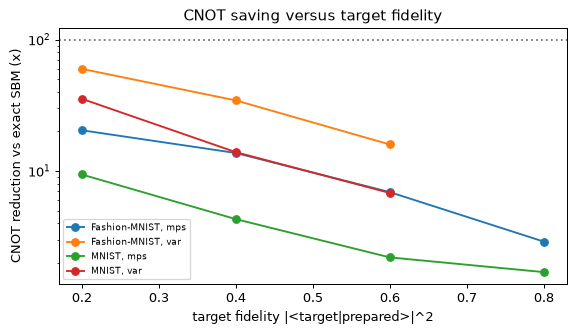

In [23]:
rows = []
t0 = time.time()
for ds in DATASETS:
    tg = DATA[ds]["psi_te"][:N_SWEEP]
    assert np.all(DEPTH[ds]["var"]["cx"] <= 8 * ENC[ds]["var"]["te"]["L"][:N_DEPTH].numpy()) and np.all(DEPTH[ds]["mps"]["cx"] <= 24 * ENC[ds]["mps"]["te"]["L"][:N_DEPTH].numpy())
    cx_exact = DEPTH[ds]["exact"]["cx"].mean()
    for target in sorted(set(SWEEP_MPS + SWEEP_VAR + [FID_TARGET])):
        res = {}
        if target == FID_TARGET:
            pm_f, K = ENC[ds]["mps"]["te"]["fid"][:N_SWEEP], ENC[ds]["mps"]["te"]["L"][:N_SWEEP]; pv_f, Lv = ENC[ds]["var"]["te"]["fid"][:N_SWEEP], ENC[ds]["var"]["te"]["L"][:N_SWEEP]
        else:
            pm_f, K = (lambda r: (r[1], r[2]))(mps_encode(tg, NQ, target, MPS_MAX_LAYERS)) if target in SWEEP_MPS else (None, None)
            pv_f, Lv = (lambda r: (r[1], r[2]))(var_encode(tg, NQ, target, ENC_STEPS, ENC_LR, ENC_MAX_LAYERS, SEED)) if target in SWEEP_VAR else (None, None)
        for name, f, L, per in (("mps", pm_f, K, 24), ("var", pv_f, Lv, 8)):
            if L is None: continue
            rows.append(dict(dataset=SPECS[ds]["title"], target_fidelity=target, encoder=name, mean_fidelity=round(float(f.mean()), 3), mean_layers=round(float(L.float().mean()), 2),
                             mean_CNOT=round(per * float(L.float().mean()), 1), exact_CNOT=round(float(cx_exact), 0), reduction=round(float(cx_exact) / (per * float(L.float().mean())), 1)))
    print(f"{SPECS[ds]['title']} sweep done [{time.time() - t0:.0f} s]")
SWEEP_TABLE = pd.DataFrame(rows).sort_values(["dataset", "encoder", "target_fidelity"]); display(SWEEP_TABLE)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (ds, enc), g in SWEEP_TABLE.groupby(["dataset", "encoder"]):
    ax.plot(g["target_fidelity"], g["reduction"], "o-", label=f"{ds}, {enc}")
ax.axhline(100, color="gray", ls=":"); ax.set_yscale("log"); ax.set_xlabel("target fidelity |<target|prepared>|^2"); ax.set_ylabel("CNOT reduction vs exact SBM (x)")
ax.set_title("CNOT saving versus target fidelity"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 7. Robustness of the QVC to random pixel noise (claim C2, Fig. 1b)

Uniform random noise of growing amplitude is added to the test pixels before the exact encoding. We plot the accuracy of the exact-encoding QVC and the mean fidelity
between the clean and the noisy encoded states. The paper finds the accuracy "roughly constant" while the fidelity falls to about 60 %.

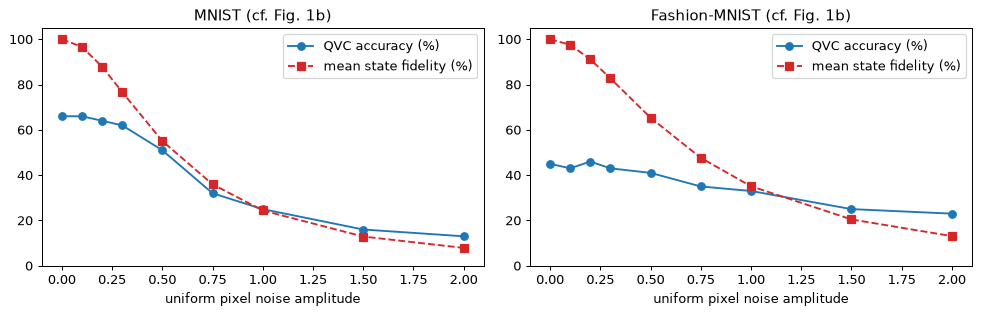

,amplitude,fidelity,accuracy,dataset
0,0.00,1.000,0.66,MNIST
1,0.10,0.966,0.66,MNIST
2,0.20,0.879,0.64,MNIST
3,0.30,0.767,0.62,MNIST
4,0.50,0.551,0.51,MNIST
5,0.75,0.360,0.32,MNIST
6,1.00,0.244,0.25,MNIST
7,1.50,0.129,0.16,MNIST
8,2.00,0.079,0.13,MNIST


,amplitude,fidelity,accuracy,dataset
0,0.00,1.000,0.45,Fashion-MNIST
1,0.10,0.975,0.43,Fashion-MNIST
2,0.20,0.911,0.46,Fashion-MNIST
3,0.30,0.827,0.43,Fashion-MNIST
4,0.50,0.654,0.41,Fashion-MNIST
5,0.75,0.476,0.35,Fashion-MNIST
6,1.00,0.351,0.33,Fashion-MNIST
7,1.50,0.204,0.25,Fashion-MNIST
8,2.00,0.131,0.23,Fashion-MNIST


In [24]:
PN = {}
for ds in DATASETS:
    model = MODELS[ds]["exact"][0]; X = DATA[ds]["Xte"]; g = torch.Generator().manual_seed(SEED)
    noise = 2 * torch.rand(X.shape, generator=g) - 1                                  # CHOICE: no clipping of the noisy pixels
    rows = []
    for a in PIXEL_NOISE:
        psi_n = amp_encode(X + a * noise, NQ)
        rows.append(dict(amplitude=a, fidelity=float(fidelity(DATA[ds]["psi_te"], psi_n).mean()), accuracy=acc_of(model, psi_n, DATA[ds]["yte"])))
    PN[ds] = pd.DataFrame(rows)
fig, axs = plt.subplots(1, len(DATASETS), figsize=(11, 3.6))
for ax, ds in zip(axs, DATASETS):
    ax.plot(PN[ds]["amplitude"], 100 * PN[ds]["accuracy"], "o-", label="QVC accuracy (%)"); ax.plot(PN[ds]["amplitude"], 100 * PN[ds]["fidelity"], "s--", color="tab:red", label="mean state fidelity (%)")
    ax.set_xlabel("uniform pixel noise amplitude"); ax.set_title(SPECS[ds]["title"] + " (cf. Fig. 1b)"); ax.legend(); ax.set_ylim(0, 105)
plt.tight_layout(); plt.show()
for ds in DATASETS: display(PN[ds].round(3).assign(dataset=SPECS[ds]["title"]))

## 8. Adversarial robustness: attacks computed on a classical network and transferred (claims C3-C5, Fig. 2c,d)

A ConvNet and a ResNet-18 are trained on the raw pixels. PGD (l-infinity, three steps of size eps/3, random start, clipping to [0, 1]) is run **on the ConvNet**; the perturbed
images are then given to the ConvNet itself (white box), to the ResNet-18 and to the three QVCs. For the approximately encoded QVCs the adversarial image goes through the
same approximate preparation first, so the encoder's error acts on the adversarial perturbation as well. SVMs on the same encoded vectors are the classical baseline on identical inputs.

MNIST: clean test accuracy ConvNet 87.0 %, ResNet-18 95.0 %  [68 s]


  eps 0.00: ConvNet (white box) 87.0, ResNet-18 95.0, QVC exact 66.0, QVC mps 61.0, QVC var 54.0   [109 s]


  eps 0.15: ConvNet (white box) 6.0, ResNet-18 86.0, QVC exact 61.0, QVC mps 15.0, QVC var 34.0   [109 s]


  eps 0.30: ConvNet (white box) 0.0, ResNet-18 58.0, QVC exact 32.0, QVC mps 11.0, QVC var 20.0   [110 s]


Fashion-MNIST: clean test accuracy ConvNet 62.0 %, ResNet-18 55.0 %  [179 s]


  eps 0.00: ConvNet (white box) 62.0, ResNet-18 55.0, QVC exact 45.0, QVC mps 38.0, QVC var 40.0   [197 s]


  eps 0.15: ConvNet (white box) 5.0, ResNet-18 34.0, QVC exact 30.0, QVC mps 23.0, QVC var 17.0   [198 s]


  eps 0.30: ConvNet (white box) 0.0, ResNet-18 12.0, QVC exact 15.0, QVC mps 14.0, QVC var 9.0   [198 s]


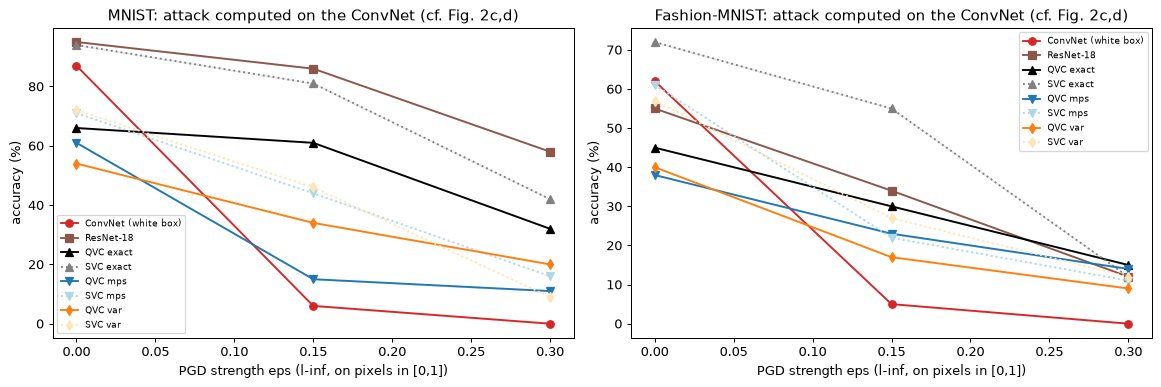

,dataset,model,eps=0.0,eps=0.15,eps=0.3
0,MNIST,ConvNet (white box),87.0,6.0,0.0
1,MNIST,ResNet-18,95.0,86.0,58.0
2,MNIST,QVC exact,66.0,61.0,32.0
3,MNIST,SVC exact,94.0,81.0,42.0
4,MNIST,QVC mps,61.0,15.0,11.0
5,MNIST,SVC mps,71.0,44.0,16.0
6,MNIST,QVC var,54.0,34.0,20.0
7,MNIST,SVC var,72.0,46.0,9.0
8,Fashion-MNIST,ConvNet (white box),62.0,5.0,0.0
9,Fashion-MNIST,ResNet-18,55.0,34.0,12.0


mean fidelity between the exact encoding of the (adversarial) image and the prepared state:


,MNIST mps,MNIST var,Fashion-MNIST mps,Fashion-MNIST var
0.00,0.613,0.621,0.669,0.640
0.15,0.620,0.624,0.674,0.641
0.30,0.638,0.627,0.708,0.668


In [25]:
class ConvNet(nn.Module):
    def __init__(self, ncls=10, side=28):
        super().__init__(); self.side = side
        self.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.AdaptiveAvgPool2d(3), nn.Flatten(), nn.Linear(288, 64), nn.ReLU(), nn.Linear(64, ncls))
    def forward(self, x): return self.f(x.reshape(-1, 1, self.side, self.side))

class Block(nn.Module):
    def __init__(self, i, o, stride):
        super().__init__()
        self.c1 = nn.Conv2d(i, o, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(o); self.c2 = nn.Conv2d(o, o, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(o)
        self.sh = None if (stride == 1 and i == o) else nn.Sequential(nn.Conv2d(i, o, 1, stride, bias=False), nn.BatchNorm2d(o))
    def forward(self, x):
        y = self.b2(self.c2(F.relu(self.b1(self.c1(x)))))
        return F.relu(y + (x if self.sh is None else self.sh(x)))

class ResNet18(nn.Module):
    """ResNet-18 layout (4 stages x 2 basic blocks) with base width w (CHOICE: 16 instead of 64) for 1-channel images."""
    def __init__(self, ncls=10, side=28, w=RES_WIDTH):
        super().__init__(); self.side = side
        cfg = [(w, w, 1), (w, w, 1), (w, 2 * w, 2), (2 * w, 2 * w, 1), (2 * w, 4 * w, 2), (4 * w, 4 * w, 1), (4 * w, 8 * w, 2), (8 * w, 8 * w, 1)]
        self.stem = nn.Sequential(nn.Conv2d(1, w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), nn.ReLU())
        self.blocks = nn.Sequential(*[Block(*c) for c in cfg]); self.fc = nn.Linear(8 * w, ncls)
    def forward(self, x):
        h = self.blocks(self.stem(x.reshape(-1, 1, self.side, self.side)))
        return self.fc(F.adaptive_avg_pool2d(h, 1).flatten(1))

def train_cnn(cls, X, y, epochs, seed, side, ncls, bs=64, lr=2e-3):          # CHOICE: lr and batch size of the classical networks
    torch.manual_seed(seed); m = cls(ncls=ncls, side=side); opt = torch.optim.Adam(m.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; loss = F.cross_entropy(m(X[idx]), y[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

@torch.no_grad()
def acc_cnn(m, X, y, bs=500):
    return float(torch.cat([m(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)]).eq(y).float().mean())

def pgd(logit_fn, X, y, eps, steps, seed, bs=100):
    """l-infinity PGD (paper Eq. 9): random start in the eps-ball, `steps` signed-gradient steps of size eps/steps that increase the loss, projection, clip to [0,1]."""
    if eps == 0: return X.clone()
    g = torch.Generator().manual_seed(seed); out = []
    for s in range(0, len(X), bs):
        x, t = X[s:s + bs], y[s:s + bs]; alpha = eps / steps
        xa = (x + (2 * torch.rand(x.shape, generator=g) - 1) * eps).clamp(0, 1)
        for _ in range(steps):
            xa = xa.detach().requires_grad_(True)
            gr, = torch.autograd.grad(F.cross_entropy(logit_fn(xa), t), xa)
            xa = (x + (xa.detach() + alpha * gr.sign() - x).clamp(-eps, eps)).clamp(0, 1)
        out.append(xa.detach())
    return torch.cat(out)

def encode_adv(Xa):
    """Amplitude-encode (exact) and approximately prepare (MPS, variational) a batch of perturbed images (one big batch: much faster than many small ones)."""
    pe = amp_encode(Xa, NQ); res = {"exact": (pe, torch.ones(len(pe)))}
    for m in ("mps", "var"):
        psi, f, L, _ = encode_all(m, pe, NQ, FID_TARGET, SEED + 7); res[m] = (psi, f)
    return res

CLS = {}; ADV = {ds: {} for ds in DATASETS}; ADVFID = {ds: {} for ds in DATASETS}; XADV = {}
t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; XT, YT = d["Xte"][:N_ATK], d["yte"][:N_ATK]                  # the attacked images
    cnn = train_cnn(ConvNet, d["Xtr"], d["ytr"], CNN_EPOCHS, SEED, IMG, N_CLASSES)
    res = train_cnn(ResNet18, d["Xtr"], d["ytr"], CNN_EPOCHS, SEED, IMG, N_CLASSES)
    CLS[ds] = dict(cnn=cnn, res=res)
    print(f"{SPECS[ds]['title']}: clean test accuracy ConvNet {100 * acc_cnn(cnn, d['Xte'], d['yte']):.1f} %, ResNet-18 {100 * acc_cnn(res, d['Xte'], d['yte']):.1f} %  [{time.time() - t0:.0f} s]")
    for eps in EPS_LIST:
        XADV[(ds, eps)] = pgd(cnn, XT, YT, eps, PGD_STEPS, SEED)                 # attack computed on the ConvNet
    pos = [e for e in EPS_LIST if e > 0]
    big = encode_adv(torch.cat([XADV[(ds, e)] for e in pos])) if pos else None   # approximate preparation of all adversarial sets in one go
    for k, eps in enumerate(EPS_LIST):
        Xa = XADV[(ds, eps)]; A = ADV[ds]
        A.setdefault("ConvNet (white box)", {})[eps] = [acc_cnn(cnn, Xa, YT)]; A.setdefault("ResNet-18", {})[eps] = [acc_cnn(res, Xa, YT)]
        if eps > 0:
            j = pos.index(eps); sl = slice(j * N_ATK, (j + 1) * N_ATK); enc = {m: (big[m][0][sl], big[m][1][sl]) for m in big}
        else:
            enc = {"exact": (d["psi_te"][:N_ATK], torch.ones(N_ATK)), "mps": (ENC[ds]["mps"]["te"]["psi"][:N_ATK], ENC[ds]["mps"]["te"]["fid"][:N_ATK]), "var": (ENC[ds]["var"]["te"]["psi"][:N_ATK], ENC[ds]["var"]["te"]["fid"][:N_ATK])}
        for m in ("exact", "mps", "var"):
            psi, f = enc[m]
            A.setdefault(f"QVC {m}", {})[eps] = [acc_of(mod, psi, YT) for mod in MODELS[ds][m]]
            A.setdefault(f"SVC {m}", {})[eps] = [float(BASE[ds][m]["svc"].score(feats(psi), YT.numpy()))]
            ADVFID[ds].setdefault(m, {})[eps] = float(fidelity(enc["exact"][0], psi).mean())
        print(f"  eps {eps:.2f}: " + ", ".join(f"{k2} {100 * np.mean(v[eps]):.1f}" for k2, v in A.items() if k2.startswith(("ConvNet", "ResNet", "QVC"))) + f"   [{time.time() - t0:.0f} s]")#%% code
STY = {"ConvNet (white box)": ("tab:red", "o-"), "ResNet-18": ("tab:brown", "s-"), "QVC exact": ("k", "^-"), "QVC mps": ("tab:blue", "v-"), "QVC var": ("tab:orange", "d-"),
       "SVC exact": ("gray", "^:"), "SVC mps": ("lightblue", "v:"), "SVC var": ("moccasin", "d:")}
fig, axs = plt.subplots(1, len(DATASETS), figsize=(13, 4.4))
for ax, ds in zip(axs, DATASETS):
    for k, v in ADV[ds].items():
        col, st = STY[k]; ys = np.array([100 * np.mean(v[e]) for e in EPS_LIST]); sd = np.array([100 * np.std(v[e]) for e in EPS_LIST])
        ax.plot(EPS_LIST, ys, st, color=col, label=k); ax.fill_between(EPS_LIST, ys - sd, ys + sd, color=col, alpha=0.15)
    ax.set_xlabel("PGD strength eps (l-inf, on pixels in [0,1])"); ax.set_ylabel("accuracy (%)"); ax.set_title(f"{SPECS[ds]['title']}: attack computed on the ConvNet (cf. Fig. 2c,d)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for ds in DATASETS:
    for k, v in ADV[ds].items():
        rows.append(dict(dataset=SPECS[ds]["title"], model=k, **{f"eps={e}": f"{100 * np.mean(v[e]):.1f}" + (f" +- {100 * np.std(v[e]):.1f}" if len(v[e]) > 1 else "") for e in EPS_LIST}))
ADV_TABLE = pd.DataFrame(rows); display(ADV_TABLE)
print("mean fidelity between the exact encoding of the (adversarial) image and the prepared state:")
display(pd.DataFrame({f"{SPECS[ds]['title']} {m}": {e: round(ADVFID[ds][m][e], 3) for e in EPS_LIST} for ds in DATASETS for m in ("mps", "var")}))

## 9. Attacks computed on the QVC itself (claim C6, Fig. S5)

The same PGD, but the gradient is taken through the *exact-encoding QVC* (pixels -> Eq. 1 -> circuit -> scores, all differentiable in the simulator). The examples are then fed to that QVC
(white box), to the approximately encoded QVCs (after approximate preparation) and to the classical networks (transfer).

MNIST done [38 s]


Fashion-MNIST done [51 s]


,dataset,model,eps=0.2
0,MNIST,"QVC exact (white box, seed 0)",0.0
1,MNIST,QVC mps (transfer),14.0
2,MNIST,QVC var (transfer),32.0
3,MNIST,ConvNet (transfer),61.0
4,MNIST,ResNet-18 (transfer),58.0
5,Fashion-MNIST,"QVC exact (white box, seed 0)",0.0
6,Fashion-MNIST,QVC mps (transfer),17.0
7,Fashion-MNIST,QVC var (transfer),15.0
8,Fashion-MNIST,ConvNet (transfer),40.0
9,Fashion-MNIST,ResNet-18 (transfer),32.0


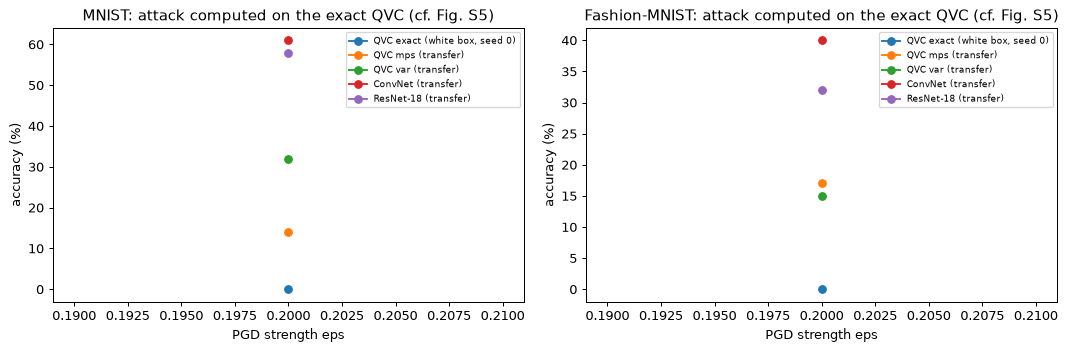

In [26]:
QADV = {ds: {} for ds in DATASETS}
t0 = time.time()
for ds in DATASETS:
    d = DATA[ds]; model = MODELS[ds]["exact"][0]; XT, YT = d["Xte"][:N_ATK], d["yte"][:N_ATK]
    Xq = {eps: pgd(lambda x: model(amp_encode(x, NQ)), XT, YT, eps, PGD_STEPS, SEED, bs=100) for eps in EPS_QATT}      # gradient through the exact pipeline
    big = encode_adv(torch.cat([Xq[e] for e in EPS_QATT]))
    for j, eps in enumerate(EPS_QATT):
        sl = slice(j * N_ATK, (j + 1) * N_ATK); enc = {m: (big[m][0][sl], big[m][1][sl]) for m in big}; A = QADV[ds]; Xa = Xq[eps]
        A.setdefault("QVC exact (white box, seed 0)", {})[eps] = acc_of(model, enc["exact"][0], YT)
        for m in ("mps", "var"):
            A.setdefault(f"QVC {m} (transfer)", {})[eps] = float(np.mean([acc_of(mod, enc[m][0], YT) for mod in MODELS[ds][m]]))
        A.setdefault("ConvNet (transfer)", {})[eps] = acc_cnn(CLS[ds]["cnn"], Xa, YT); A.setdefault("ResNet-18 (transfer)", {})[eps] = acc_cnn(CLS[ds]["res"], Xa, YT)
        if N_SEEDS > 1:
            A.setdefault("QVC exact (other seeds, transfer)", {})[eps] = float(np.mean([acc_of(mod, enc["exact"][0], YT) for mod in MODELS[ds]["exact"][1:]]))
    print(f"{SPECS[ds]['title']} done [{time.time() - t0:.0f} s]")
rows = []
for ds in DATASETS:
    for k, v in QADV[ds].items(): rows.append(dict(dataset=SPECS[ds]["title"], model=k, **{f"eps={e}": f"{100 * v[e]:.1f}" for e in EPS_QATT}))
QADV_TABLE = pd.DataFrame(rows); display(QADV_TABLE)
fig, axs = plt.subplots(1, len(DATASETS), figsize=(12, 4))
for ax, ds in zip(axs, DATASETS):
    for k, v in QADV[ds].items(): ax.plot(EPS_QATT, [100 * v[e] for e in EPS_QATT], "o-", label=k)
    ax.set_xlabel("PGD strength eps"); ax.set_ylabel("accuracy (%)"); ax.set_title(f"{SPECS[ds]['title']}: attack computed on the exact QVC (cf. Fig. S5)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. Noisy circuits: why shallow encoders matter (claim C7, Fig. 3a)

The paper adds depolarising noise to every two-qubit gate and finds that the approximately encoded models keep their accuracy at noise levels one to two orders of magnitude higher
than the exact model. We do the same with an exact density-matrix simulation (Qiskit Aer): the full circuit (transpiled encoder followed by the QVC, with the trained angles) is run on `N_NOISE`
test images with a two-qubit depolarising error of probability `p` after each CNOT, single-qubit gates are ideal, and the class scores are the Pauli-Z expectation values from the output probabilities.
The QVC itself also contains `L x 8` CNOTs and suffers from the noise; this is the same in all three encodings.

MNIST          exact: accuracy p=0: 60%, p=0.001: 60%, p=0.003: 60%, p=0.01: 50% | same prediction as noiseless 100%, 100%, 100%, 50%   [113 s]


MNIST          mps  : accuracy p=0: 60%, p=0.001: 60%, p=0.003: 60%, p=0.01: 50% | same prediction as noiseless 100%, 100%, 100%, 70%   [134 s]


MNIST          var  : accuracy p=0: 50%, p=0.001: 50%, p=0.003: 50%, p=0.01: 40% | same prediction as noiseless 100%, 100%, 100%, 80%   [155 s]


Fashion-MNIST  exact: accuracy p=0: 40%, p=0.001: 30%, p=0.003: 20%, p=0.01: 30% | same prediction as noiseless 100%, 80%, 70%, 60%   [264 s]


Fashion-MNIST  mps  : accuracy p=0: 50%, p=0.001: 50%, p=0.003: 50%, p=0.01: 60% | same prediction as noiseless 100%, 100%, 100%, 50%   [277 s]


Fashion-MNIST  var  : accuracy p=0: 60%, p=0.001: 60%, p=0.003: 50%, p=0.01: 40% | same prediction as noiseless 100%, 100%, 90%, 70%   [293 s]


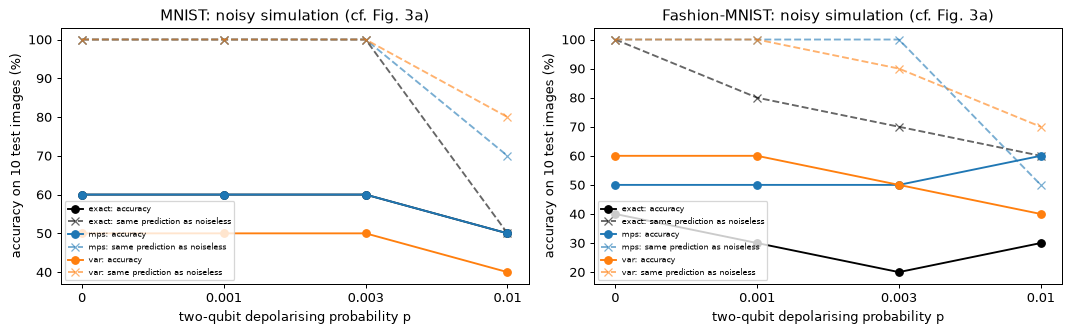

In [27]:
def noisy_scores(circs, qvc, p, nq, ncls):
    """Run encoder circuits + QVC circuit under CNOT depolarising noise p; return class scores [n, ncls]."""
    full = []
    for c in circs:
        f = c.compose(qvc); f.save_probabilities(); full.append(f)
    if p == 0: sim = AerSimulator(method="statevector", max_parallel_threads=2)
    else:
        nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(p, 2), ["cx"])
        sim = AerSimulator(method="density_matrix", noise_model=nm, max_parallel_threads=2)
    res = sim.run(full).result()
    return np.array([zexp_from_probs(res.data(k)["probabilities"], nq, ncls) for k in range(len(full))])

NOISE = {ds: {m: [] for m in ("exact", "mps", "var")} for ds in DATASETS}; NOISE_AGR = {ds: {m: [] for m in ("exact", "mps", "var")} for ds in DATASETS}
t0 = time.time()
for ds in DATASETS:
    y = DATA[ds]["yte"][:N_NOISE].numpy()
    for m in ("exact", "mps", "var"):
        qv = qvc_circuit(MODELS[ds][m][0].theta.detach().numpy(), NQ)
        pred0 = None
        for p in NOISE_LEVELS:
            z = noisy_scores(CIRCS[ds][m][:N_NOISE], qv, p, NQ, N_CLASSES); pred = z.argmax(1)
            if pred0 is None: pred0 = pred                                         # NOISE_LEVELS[0] = 0: the noiseless prediction
            NOISE[ds][m].append(float((pred == y).mean())); NOISE_AGR[ds][m].append(float((pred == pred0).mean()))
        print(f"{SPECS[ds]['title']:14s} {m:5s}: accuracy " + ", ".join(f"p={p:g}: {100 * a:.0f}%" for p, a in zip(NOISE_LEVELS, NOISE[ds][m])) + " | same prediction as noiseless " + ", ".join(f"{100 * a:.0f}%" for a in NOISE_AGR[ds][m]) + f"   [{time.time() - t0:.0f} s]")
fig, axs = plt.subplots(1, len(DATASETS), figsize=(12, 3.8))
for ax, ds in zip(axs, DATASETS):
    for m, col in zip(("exact", "mps", "var"), ("k", "tab:blue", "tab:orange")):
        ax.plot(range(len(NOISE_LEVELS)), [100 * a for a in NOISE[ds][m]], "o-", color=col, label=f"{m}: accuracy")
        ax.plot(range(len(NOISE_LEVELS)), [100 * a for a in NOISE_AGR[ds][m]], "x--", color=col, alpha=0.6, label=f"{m}: same prediction as noiseless")
    ax.set_xticks(range(len(NOISE_LEVELS))); ax.set_xticklabels([f"{p:g}" for p in NOISE_LEVELS]); ax.set_xlabel("two-qubit depolarising probability p")
    ax.set_ylabel(f"accuracy on {N_NOISE} test images (%)"); ax.set_title(f"{SPECS[ds]['title']}: noisy simulation (cf. Fig. 3a)"); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

## 11. The "Shapes" experiment (claims C8, C9, Fig. 3b-e)

Squares and crosses on an 8 x 8 grid need only five qubits. We prepare them exactly and approximately (target fidelity 70 %), count CNOTs (Fig. 3c), train a three-layer QVC for every encoding,
attack a ConvNet and transfer the examples (eps = 0.1 as in the paper, and 0.3), and run the full circuits in a noisy density-matrix simulation as a stand-in for `ibm_algiers`
(which we cannot access): two-qubit depolarising noise `SH_P` on every CNOT. A real device has more error sources, so this can only show the *direction* of the effect.

Shapes mps: mean fidelity 0.897, mean layers 1.08  [0 s]


Shapes var: mean fidelity 0.834, mean layers 1.97  [4 s]


Shapes ConvNet clean test accuracy: 1.0


,ConvNet,QVC exact,"QVC exact, noisy p=0.01",QVC mps,"QVC mps, noisy p=0.01",QVC var,"QVC var, noisy p=0.01"
PGD eps,,,,,,,
0.0,100.0,75.0,75.0,80.0,80.0,80.0,80.0
0.1,61.7,80.0,80.0,80.0,76.7,71.7,71.7
0.3,0.0,71.7,70.0,68.3,71.7,31.7,31.7


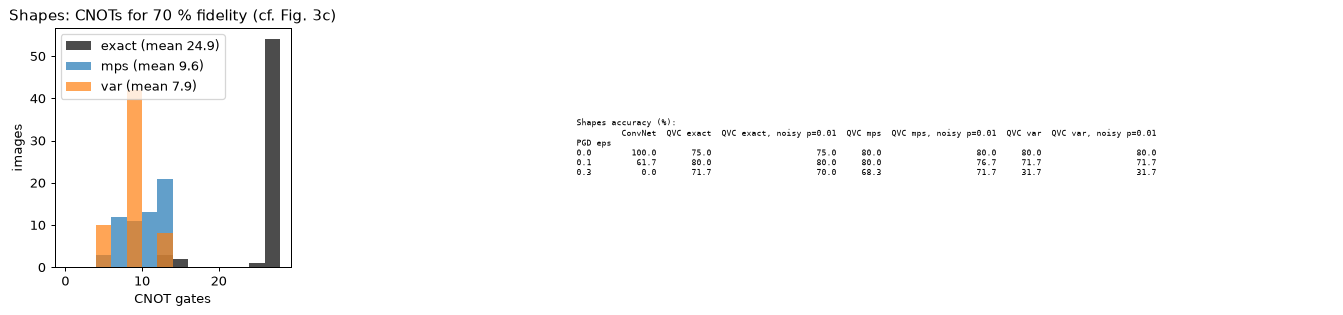

Shapes (60 test images): mean CNOTs exact 24.9, MPS 9.6, variational 7.9  [38 s]


In [28]:
nq = SH_NQ; t0 = time.time()
sh_ex_tr, sh_ex_te = amp_encode(SH["Xtr"], nq), amp_encode(SH["Xte"], nq)
SHENC = {}
for m in ("mps", "var"):
    SHENC[m] = {}
    for sp, tgt in (("tr", sh_ex_tr), ("te", sh_ex_te)):
        psi, f, L, kept = encode_all(m, tgt, nq, SH_TARGET, SEED, keep=(len(tgt) if sp == "te" and len(tgt) <= ENC_CHUNK else 0))
        SHENC[m][sp] = dict(psi=psi, fid=f, L=L, kept=kept)
    print(f"Shapes {m}: mean fidelity {float(SHENC[m]['te']['fid'].mean()):.3f}, mean layers {float(SHENC[m]['te']['L'].float().mean()):.2f}  [{time.time() - t0:.0f} s]")

SHC = {m: [] for m in ("exact", "mps", "var")}; SHD = {}
for i in range(SH_TEST):
    SHC["exact"].append(transpile_basis(exact_circuit(sh_ex_te[i].numpy(), nq)))
    SHC["mps"].append(transpile_basis(mps_circuit(SHENC["mps"]["te"]["kept"], int(SHENC["mps"]["te"]["L"][i]), i, nq)))
    SHC["var"].append(transpile_basis(var_circuit(SHENC["var"]["te"]["kept"][i].numpy(), nq)))
for m in SHC: SHD[m] = np.array([c.count_ops().get("cx", 0) for c in SHC[m]])
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
bins = np.arange(0, max(SHD["exact"].max(), 10) + 4, 2)
for m, col in zip(("exact", "mps", "var"), ("k", "tab:blue", "tab:orange")):
    axs[0].hist(SHD[m], bins=bins, alpha=0.7, color=col, label=f"{m} (mean {SHD[m].mean():.1f})")
axs[0].set_xlabel("CNOT gates"); axs[0].set_ylabel("images"); axs[0].set_title("Shapes: CNOTs for 70 % fidelity (cf. Fig. 3c)"); axs[0].legend()
SHCLS = train_cnn(ConvNet, SH["Xtr"], SH["ytr"], 15, SEED, 8, 2)
print("Shapes ConvNet clean test accuracy:", acc_cnn(SHCLS, SH["Xte"], SH["yte"]))
SHQ = {}
for m in ("exact", "mps", "var"):
    ptr = sh_ex_tr if m == "exact" else SHENC[m]["tr"]["psi"]
    SHQ[m], _ = train_qvc(ptr, SH["ytr"], ptr[:50], SH["ytr"][:50], SEED, nq, SH_LAYERS, 2, SH_EPOCHS, 50, 0.05)   # the 50 "validation" images are only monitored
SH_RES = {}
for eps in [0.0, 0.1, 0.3]:
    Xa = pgd(SHCLS, SH["Xte"], SH["yte"], eps, PGD_STEPS, SEED)
    pe = amp_encode(Xa, nq); SH_RES[eps] = {"ConvNet": acc_cnn(SHCLS, Xa, SH["yte"])}
    for m in ("exact", "mps", "var"):
        if eps == 0: psi, kept, Lv = (pe, None, None) if m == "exact" else (SHENC[m]["te"]["psi"], SHENC[m]["te"]["kept"], SHENC[m]["te"]["L"])
        elif m == "exact": psi, kept, Lv = pe, None, None
        else: psi, f, Lv, kept = encode_all(m, pe, nq, SH_TARGET, SEED + 3, keep=len(pe))
        SH_RES[eps][f"QVC {m}"] = acc_of(SHQ[m], psi, SH["yte"])
        if m == "exact": circs = [transpile_basis(exact_circuit(pe[i].numpy(), nq)) for i in range(SH_TEST)]
        elif m == "mps": circs = [transpile_basis(mps_circuit(kept, int(Lv[i]), i, nq)) for i in range(SH_TEST)]
        else: circs = [transpile_basis(var_circuit(kept[i].numpy(), nq)) for i in range(SH_TEST)]
        z = noisy_scores(circs, qvc_circuit(SHQ[m].theta.detach().numpy(), nq), SH_P, nq, 2)
        SH_RES[eps][f"QVC {m}, noisy p={SH_P:g}"] = float((z.argmax(1) == SH["yte"].numpy()).mean())
SH_TABLE = pd.DataFrame(SH_RES).T.mul(100).round(1); SH_TABLE.index.name = "PGD eps"; display(SH_TABLE)
axs[1].axis("off"); axs[2].axis("off")
axs[1].text(0, 0.5, "Shapes accuracy (%):\n" + SH_TABLE.to_string(), family="monospace", fontsize=6.5, va="center")
plt.tight_layout(); plt.show()
print(f"Shapes ({SH_TEST} test images): mean CNOTs exact {SHD['exact'].mean():.1f}, MPS {SHD['mps'].mean():.1f}, variational {SHD['var'].mean():.1f}  [{time.time() - t0:.0f} s]")

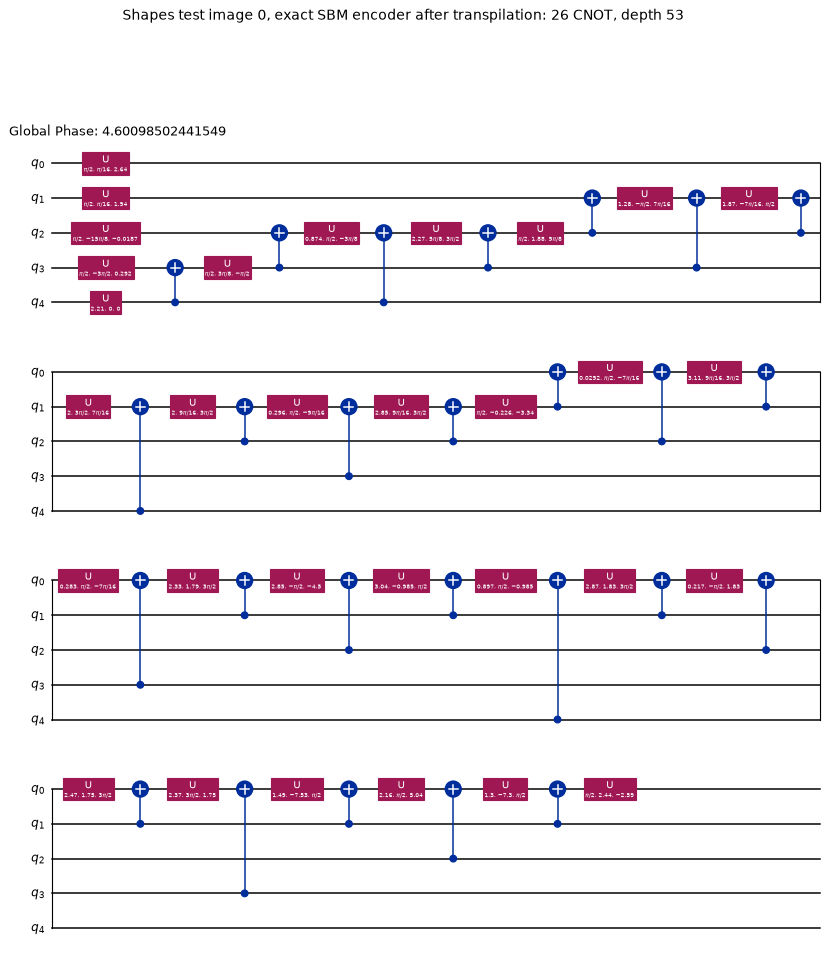

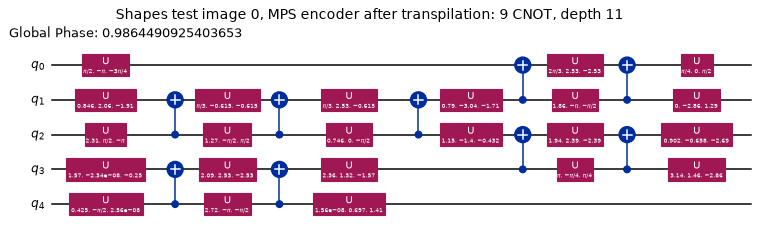

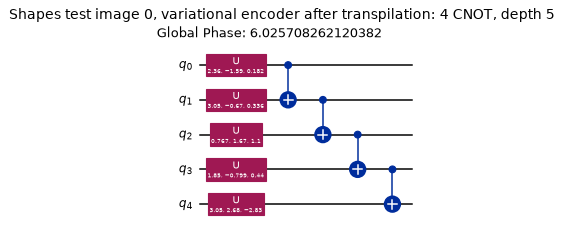

In [29]:
# The three 5-qubit Shapes encoders for one test image, fully transpiled to {cx, u} (these are the circuits that are simulated above).
for m, lab in [("exact", "exact SBM"), ("mps", "MPS"), ("var", "variational")]:
    show(SHC[m][0], f"Shapes test image 0, {lab} encoder after transpilation: {SHC[m][0].count_ops().get('cx', 0)} CNOT, depth {SHC[m][0].depth()}", fold=22, scale=0.6)

## 12. Side by side with the paper

The paper prints no numbers for these figures, so each claim is turned into a testable statement with an explicit threshold (written next to it). "reproduced" means the statement holds
in this notebook's run; "not reached" means it does not (with the gap); "cannot be checked" means we cannot run the experiment. Budgets are far smaller than the paper's
(see the table at the top), so a "not reached" can come from the small budget as well as from the claim.

In [30]:
def pct(x): return f"{100 * x:.1f}"
EPS_POS = [e for e in EPS_LIST if e > 0]
claims = []

# C1: CNOT reduction at 60 % fidelity
r = {(ds, m): DEPTH[ds]["exact"]["cx"].mean() / DEPTH[ds][m]["cx"].mean() for ds in DATASETS for m in ("mps", "var")}
low = SWEEP_TABLE[SWEEP_TABLE["target_fidelity"] == min(SWEEP_VAR)]
claims.append(("C1 (Fig. 1d)", "approximate encoders need ~100x (two orders of magnitude) fewer CNOTs than exact SBM at 60 % fidelity (threshold: >= 50x)",
               "; ".join(f"{SPECS[ds]['title']} {m}: {r[(ds, m)]:.0f}x ({DEPTH[ds]['exact']['cx'].mean():.0f} -> {DEPTH[ds][m]['cx'].mean():.0f} CNOT)" for ds in DATASETS for m in ("mps", "var"))
               + f". At a target of only {min(SWEEP_VAR)}: " + "; ".join(f"{a} {b} {c:.0f}x" for a, b, c in zip(low["dataset"], low["encoder"], low["reduction"])),
               "reproduced" if min(r.values()) >= 50 else ("not reached (reduction is " + f"{min(r.values()):.0f}-{max(r.values()):.0f}x at 60 %, threshold 50x)")))
# C2: robustness to random pixel noise
parts, ok = [], True
for ds in DATASETS:
    t = PN[ds]; clean = t.iloc[0]["accuracy"]; row = t.iloc[(t["fidelity"] - 0.65).abs().argmin()]
    drop = clean - row["accuracy"]; parts.append(f"{SPECS[ds]['title']}: fidelity {row['fidelity']:.2f} -> accuracy {pct(row['accuracy'])} % vs clean {pct(clean)} % (drop {100 * drop:.1f})"); ok &= bool(drop <= 0.05)
claims.append(("C2 (Fig. 1b)", "accuracy stays roughly constant while the state fidelity drops to ~60-70 % (threshold: drop <= 5 points)", "; ".join(parts), "reproduced" if ok else "not reached"))

# C3: clean accuracy of approximate vs exact
gaps = {(ds, m): np.mean(CLEAN[ds]["exact"]) - np.mean(CLEAN[ds][m]) for ds in DATASETS for m in ("mps", "var")}
claims.append(("C3 (Fig. 2c,d)", "approximate encodings keep comparable clean accuracy (threshold: loss <= 5 points)",
               "; ".join(f"{SPECS[ds]['title']} exact {pct(np.mean(CLEAN[ds]['exact']))} %, {m} {pct(np.mean(CLEAN[ds][m]))} % (gap {100 * gaps[(ds, m)]:.1f})" for ds in DATASETS for m in ("mps", "var")),
               "reproduced" if max(gaps.values()) <= 0.05 else f"not reached (largest loss {100 * max(gaps.values()):.1f} points)"))

# C4: QVC more robust than classical nets against the transferred ConvNet attack
parts, ok = [], True
for ds in DATASETS:
    a = {k: np.mean(ADV[ds][k][EPS_MAIN]) for k in ("QVC exact", "ConvNet (white box)", "ResNet-18")}
    parts.append(f"{SPECS[ds]['title']} @eps={EPS_MAIN}: QVC {pct(a['QVC exact'])} %, ResNet-18 {pct(a['ResNet-18'])} %, ConvNet {pct(a['ConvNet (white box)'])} %")
    ok &= bool(a["QVC exact"] - max(a["ResNet-18"], a["ConvNet (white box)"]) >= 0.10)
claims.append(("C4 (Fig. 2c,d, S5)", "QVCs resist the transferred ConvNet attack far better than ConvNet / ResNet-18 (threshold: >= 10 points above both)", "; ".join(parts), "reproduced" if ok else "not reached"))

# C5: approximate encodings slightly more robust than exact
for m, nm in (("mps", "MPS"), ("var", "variational")):
    adv = {ds: np.mean([np.mean(ADV[ds][f"QVC {m}"][e]) - np.mean(ADV[ds]["QVC exact"][e]) for e in EPS_POS]) for ds in DATASETS}
    adv_main = {ds: np.mean(ADV[ds][f"QVC {m}"][EPS_MAIN]) - np.mean(ADV[ds]["QVC exact"][EPS_MAIN]) for ds in DATASETS}
    claims.append((f"C5 {nm} (Fig. 2)", "approximately encoded QVC is slightly MORE robust than the exact one (threshold: mean adversarial accuracy advantage over eps > 0 of at least +0.5 points)",
                   "; ".join(f"{SPECS[ds]['title']}: mean advantage {100 * adv[ds]:+.1f} points (at eps={EPS_MAIN}: {100 * adv_main[ds]:+.1f})" for ds in DATASETS),
                   "reproduced" if np.mean(list(adv.values())) >= 0.005 and min(adv.values()) > -0.005 else ("not reached (not distinguishable from zero / negative)" if np.mean(list(adv.values())) > -0.01 else "not reached (approximate encoding is less robust)")))

# C6: attacks computed on the QVC
parts, ok = [], True
for ds in DATASETS:
    ex = np.mean([QADV[ds]["QVC exact (white box, seed 0)"][e] for e in EPS_QATT]); ap = {m: np.mean([QADV[ds][f"QVC {m} (transfer)"][e] for e in EPS_QATT]) for m in ("mps", "var")}
    parts.append(f"{SPECS[ds]['title']}: exact (white box) {pct(ex)} %, MPS {pct(ap['mps'])} %, variational {pct(ap['var'])} %"); ok &= bool(min(ap.values()) - ex >= 0.05)
claims.append(("C6 (Fig. S5)", "approximate QVCs partially resist attacks computed on a QVC (threshold: >= 5 points above the white-box exact QVC)", "; ".join(parts), "reproduced" if ok else "not reached"))

# C7: noise tolerance
parts, ok = [], True
for ds in DATASETS:
    best = max(max(NOISE_AGR[ds][m][k] - NOISE_AGR[ds]["exact"][k] for k in range(len(NOISE_LEVELS))) for m in ("mps", "var"))
    parts.append(f"{SPECS[ds]['title']} (same prediction as noiseless, %): exact " + "/".join(f"{100 * a:.0f}" for a in NOISE_AGR[ds]["exact"]) + " ; MPS " + "/".join(f"{100 * a:.0f}" for a in NOISE_AGR[ds]["mps"]) + " ; var " + "/".join(f"{100 * a:.0f}" for a in NOISE_AGR[ds]["var"])
                 + f" at p = {NOISE_LEVELS}"); ok &= bool(best >= 0.20)
claims.append(("C7 (Fig. 3a)", f"under CNOT depolarising noise the approximate models keep their predictions where the exact one degrades (threshold: some p with >= 20 points more unchanged predictions; {N_NOISE} images)", " | ".join(parts), "reproduced" if ok else "not reached"))
# C8: Shapes CNOT savings
rs_ = SHD["exact"].mean() / min(SHD["mps"].mean(), SHD["var"].mean())
claims.append(("C8 (Fig. 3c)", "on Shapes the approximate encoders also need considerably fewer CNOTs (threshold: >= 3x for the better one)",
               f"exact {SHD['exact'].mean():.1f}, MPS {SHD['mps'].mean():.1f}, variational {SHD['var'].mean():.1f} CNOT -> {rs_:.1f}x", "reproduced" if rs_ >= 3 else f"not reached ({rs_:.1f}x)"))
claims.append(("C9 (Fig. 3e)", "on ibm_algiers the approximate circuits give up to 96 % accuracy, the exact circuit is at chance level", "no hardware access; depolarising simulation instead: " +
               "; ".join(f"eps={e}: " + ", ".join(f"{k.replace('QVC ', '').split(',')[0]} {v:.0f}" for k, v in SH_TABLE.loc[e].items() if "noisy" in k) for e in SH_TABLE.index) + " (%)", "cannot be checked (real device); simulated trend above"))
claims.append(("GASP (Fig. 1c,d, 2c,d)", "the genetic encoder reaches comparable savings but lower fidelity", "not implemented (CPU cost)", "cannot be checked"))
VERDICTS = pd.DataFrame(claims, columns=["claim", "paper (qualitative)", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 400)
for _, row in VERDICTS.iterrows():
    print(f"[{row['claim']}] {row['paper (qualitative)']}\n    notebook: {row['this notebook']}\n    VERDICT: {row['verdict']}\n")
print(f"Total run time of the notebook: {(time.time() - T0) / 60:.1f} minutes (FAST_MODE = {FAST_MODE})")

[C1 (Fig. 1d)] approximate encoders need ~100x (two orders of magnitude) fewer CNOTs than exact SBM at 60 % fidelity (threshold: >= 50x)
    notebook: MNIST mps: 2x (502 -> 228 CNOT); MNIST var: 7x (502 -> 73 CNOT); Fashion-MNIST mps: 6x (502 -> 84 CNOT); Fashion-MNIST var: 12x (502 -> 41 CNOT). At a target of only 0.2: Fashion-MNIST mps 20x; Fashion-MNIST var 60x; MNIST mps 9x; MNIST var 35x
    VERDICT: not reached (reduction is 2-12x at 60 %, threshold 50x)

[C2 (Fig. 1b)] accuracy stays roughly constant while the state fidelity drops to ~60-70 % (threshold: drop <= 5 points)
    notebook: MNIST: fidelity 0.55 -> accuracy 51.0 % vs clean 66.0 % (drop 15.0); Fashion-MNIST: fidelity 0.65 -> accuracy 41.0 % vs clean 45.0 % (drop 4.0)
    VERDICT: not reached

[C3 (Fig. 2c,d)] approximate encodings keep comparable clean accuracy (threshold: loss <= 5 points)
    notebook: MNIST exact 66.0 %, mps 61.0 % (gap 5.0); MNIST exact 66.0 %, var 54.0 % (gap 12.0); Fashion-MNIST exact 45.0 %, mps

### What the committed run shows

This is the FAST run (400 training images per dataset, 100 test images, one seed, 8-layer QVC, 40 Adam steps per variational layer count). With 100 test images one accuracy figure has a sampling error of about 5 points, so every verdict above is indicative.

* **Depth (C1).** The exact SBM preparation of a 9-qubit state needs 502 CNOTs and has depth 1005, consistent with the paper's depth of about 2^9. At 60 % fidelity the variational encoder needs about 73 CNOTs on MNIST and 41 on Fashion-MNIST (7x and 12x fewer), the MPS encoder about 228 and 84 (2x and 6x). The direction of the paper's claim holds, the *two orders of magnitude* do not at this fidelity. They are only reached at much lower targets (about 35x and 60x at a target of 0.2, see the sweep table), and the paper does not define its fidelity precisely.
* **Accuracy (C2, C3).** Our QVC is weak (66 % MNIST, 45 % Fashion-MNIST with 400 training images; an RBF-SVM on the same state vectors reaches 94 % and 72 %). Approximate encodings cost it 5 to 12 points of clean accuracy, more than the paper's "comparable", and pixel noise that lowers the fidelity to 0.55 costs 15 points on MNIST (4 points on Fashion-MNIST at fidelity 0.65).
* **Robustness (C4, C5).** In absolute accuracy the transferred ConvNet attack hurts the exact QVC less than the ConvNet itself but it does not beat the ResNet-18 here (MNIST at eps 0.15: 61 % versus 86 %). Relative to clean accuracy the exact QVC keeps about as much as the ResNet-18 (92 % versus 91 % on MNIST, 67 % versus 62 % on Fashion-MNIST), which is the part of the paper's claim that survives. The approximately encoded QVCs were *less* robust than the exact one (C5 not reached, see the critical-reading section).
* **Attacks computed on the QVC (C6).** The exact QVC is fully broken by its own white-box attack (0 %); the approximately encoded models keep 14-32 % on MNIST and 15-17 % on Fashion-MNIST. This is expected for any model that differs from the attacked one and is weaker evidence than the transfer experiment above.
* **Noise (C7) and Shapes (C8).** Under two-qubit depolarising noise the shorter encoders change their predictions less often than the 502-CNOT exact circuit on MNIST (at p = 0.01: 50 % of the exact model's predictions unchanged versus 70-80 % for MPS and variational); on Fashion-MNIST the picture is mixed. On Shapes the approximate encoders need 3.2x fewer CNOTs. Ten images per cell make these noise results very rough, and the ibm_algiers experiment (C9) and GASP cannot be checked.

Status: **partially reproduced** (the notebook runs end to end; depth reduction, noise tolerance and the Shapes saving agree in direction, the 100x depth reduction, the accuracy preservation and the robustness gain are not reached with this budget).

## Reading the paper critically

* **The headline numbers are in figures only.** The paper gives "two orders of magnitude", "fidelities as low as 60 %", "up to 96 % on hardware", but no table of CNOT counts, accuracies or error bars, and the code is available on request. A reproduction can check the *direction and order of magnitude*, not the third digit.
* **Fidelity 60 % is a very low bar for a classifier with few classes and a very strong prior.** The datasets are easy: class information sits in coarse structure that survives a 60 %-fidelity state. This is exactly the paper's argument, but it also means the result may not transfer to data whose class information is in fine detail.
* **"More robust" can simply mean "different".** The approximate encoder acts as a fixed, image-dependent random-looking filter. A perturbation made for the ConvNet is not aligned with the features the filtered QVC uses, so the transfer attack fails more often. This is gradient obfuscation by randomness, not certified robustness: an attacker who attacks the *whole* pipeline (encoder included, e.g. with a surrogate of it) is not covered. The white-box rows in section 9 show how much a gradient through the exact pipeline helps; the approximate encoders were never attacked white-box.
* **The robustness gain was not reproduced here, and the sign even flipped.** In the committed FAST run (400 training images, 100 attacked test images, one seed, a weak classifier) the approximately encoded QVCs had 4 to 33 points *lower* adversarial accuracy than the exact one, the opposite of the paper's claim. Sampling noise at 100 images is about 5 points, so this is indicative only, but there is a plausible mechanism: the MPS encoder picks eigenvectors of reduced density matrices, a discontinuous map, so a small pixel perturbation can change the whole encoding circuit. Rerun with the full budgets and several seeds before drawing conclusions.
* **The classical baselines are weak.** ConvNet and ResNet-18 are trained without adversarial training or noise augmentation; a ConvNet trained with random smoothing would also be more robust, as the paper itself recalls (refs 36-38).
* **Hardware result.** Only a five-qubit toy task ran on a real device, after three repetitions; this notebook can only mimic it with a depolarising model.
* **Cost accounting.** Variational and GASP encoders need an optimisation *per image* (100 Adam steps per layer count, or a genetic search). If encoding is done on a classical computer this erases the "speed-up" that motivates cheap encoding; the paper's contribution is about circuit depth on the quantum device, not about total runtime.

## Exercises

1. **Fidelity target.** Change `FID_TARGET` to 0.4, 0.8 and 0.95. Plot CNOT count, clean accuracy and adversarial accuracy against the target. Where does robustness disappear?
2. **Noise instead of approximation.** Replace the approximate encoder by the exact state plus random pixel noise that gives the same fidelity (use section 7). Is the robustness gain due to the *structure* of the approximation error or just to any noise?
3. **White-box attacker.** Make the approximate encoder differentiable (the variational encoder's output is a differentiable function of the pixels if the optimiser is unrolled, or use BPDA: forward through the encoder, backward as identity) and attack the approximate QVC directly. How much of the "robustness" survives?
4. **Different classifier.** Replace `Rot` + CNOT chain by `StronglyEntanglingLayers` or fewer layers, and repeat the noise study. Does a shallower classifier narrow the gap between exact and approximate encoders?
5. **Another encoder.** Implement a tiny GASP-like search (random circuits from `{Rx, Ry, Rz, CNOT}` with `scipy.optimize.minimize` on the angles) for 5-qubit Shapes states and compare CNOT count and fidelity with the MPS and variational encoders.